# Morse-Smale complex (MSC) graph barycenter

Compute a (partial) Fused Gromov–Wasserstein barycenter for a family of **Morse-Smale complexes** loaded from `./data/`, using **adjacency** (or shortest-path / heat-kernel) relation matrices.

This notebook mirrors the demo pipeline in `graph_barycenter_adjacency.ipynb`, but replaces synthetic graph generation with MSC files (`treeNodes_*.txt` / `treeEdges_*.txt`) via `lib/graph_reader.py`.

**Pipeline**
1. Select MSC snapshots (mesh indices) from `./data/`.
2. Load each complex as a `networkx.Graph` (`read_morse_graph_txt`), merging duplicate boundary nodes by `(x,y,z)`.
3. Verify connectivity of loaded graphs.
4. Subsample along Morse paths between critical points (critical nodes always kept).
5. Visualize processed graphs in the `(x, y)` plane from file coordinates.
6. Build shortest-path relation matrices (normalized) and node features `(x,y,z)` + normalized scalar + critical-point type for FGW.
7. Choose a seed network (specified index, or the input with minimum sum of PFGW distances to the others); apply `exclude_seed` / `expand_to_largest`. Expansion reinserts nodes dropped during subsampling (longest-edge midpoint splits) without changing input graph sizes. Node masses \(p_i\) and \(p\) are the discretized arc-length measure (total mass 1).
8. Run partial FGW (PFGW) barycenter.
9. Reconstruct and visualize the barycenter graph; save the **complete** (pre-threshold) barycenter bundle under `results/barycenters/`.
10. Color transfer onto input graphs via PFGW couplings.

Downstream evaluation / sparsification lives in `msc_barycenter_evaluation.ipynb` (loads the saved bundle).


In [1]:
print("hello world")

hello world


In [2]:
# Imports (re-run this cell after editing files under lib/ — no kernel restart needed)
import importlib
import os
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

import ot

import lib.graph_reader as graph_reader
import lib.gromov as gromov
import lib.gromov_barycenter as gromov_barycenter
import lib.msc_plotting as msc_plotting
import lib.msc_color_transfer as msc_color_transfer
import lib.msc_barycenter_threshold as msc_barycenter_threshold
import lib.barycenter_io as barycenter_io
import lib.msc_barycenter_eval as msc_barycenter_eval
import lib.measure_network as measure_network

importlib.reload(graph_reader)
importlib.reload(gromov)
importlib.reload(gromov_barycenter)
importlib.reload(msc_barycenter_threshold)
importlib.reload(msc_plotting)
importlib.reload(msc_color_transfer)
importlib.reload(barycenter_io)
importlib.reload(msc_barycenter_eval)
importlib.reload(measure_network)

from lib.graph_reader import (
    read_morse_graph_txt,
    load_morse_graphs,
    prepare_graph_for_barycenter,
    summarize_graph_connectivity,
    merge_duplicate_nodes,
    sample_morse_graph,
    expand_sampled_graph_to_size,
    relation_matrix,
    compute_relation_rescale,
    apply_relation_scaling,
    reconstruct_msc_barycenter_mst_graph,
    node_height,
    msc_node_visual_type,
    draw_msc_nodes,
    msc_xy_positions,
    draw_processed_msc_graphs,
    draw_msc_graphs_overlay,
    barycenter_xy_positions,
    set_barycenter_axes_limits,
    draw_msc_barycenter_graph,
    draw_barycenter_thresholded_complete,
    draw_barycenter_colormap,
    build_complete_barycenter_graph,
    build_thresholded_barycenter_graph,
    msc_barycenter_weight_euclidean_differences,
    plot_msc_barycenter_weight_euclidean_debug,
)
from lib.msc_color_transfer import (
    DEFAULT_CORNER_COLORS,
    compute_barycenter_node_colors,
    transfer_barycenter_colors_to_inputs,
    draw_input_graph_coupling_colors,
)
from lib.barycenter_io import save_barycenter_bundle, default_barycenter_outdir
from lib.msc_barycenter_eval import pfgw_total_cost, select_seed_by_min_pfgw_sum
from ot.utils import dist
from lib.gromov import (
    partial_fused_gromov_ver1,
    partial_gromov_ver1,
    gromov_wasserstein,
    GW_dist,
    PGW_dist_with_penalty,
    PFGW_dist_with_penalty,
)
from lib.gromov_barycenter import pfgw_barycenters
from lib.measure_network import (
    arc_length_node_measure,
    duplicate_measure_nodes,
    split_measure_nodes,
)


In [3]:
# --- MSC data configuration ---
DATA_ROOT = Path("data")
# DATA_KEYWORD = "VortexStreet"
DATA_KEYWORD = "synthetic"

# Default demo: VortexStreet MSC snapshots (edit mesh_ids / folder as needed)
# MSC_DIR = DATA_ROOT / DATA_KEYWORD / "MSC_1.0"
# mesh_ids = [146, 147, 148, 149, 150]  # five nearby time steps

MSC_DIR = DATA_ROOT / DATA_KEYWORD / "DESC-MC_0.0"
mesh_ids = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


_MSC_NODE_PATTERNS = (
    ("treeNodes_monoMesh_{mesh_id}.txt", "treeEdges_monoMesh_{mesh_id}.txt"),
    ("treeNodes_synthetic_noise_{mesh_id:02d}.txt", "treeEdges_synthetic_noise_{mesh_id:02d}.txt"),
)
_MSC_ID_PATTERNS = (
    re.compile(r"treeNodes_monoMesh_(\d+)\.txt$"),
    re.compile(r"treeNodes_synthetic_noise_(\d+)\.txt$"),
)


def msc_paths(mesh_id: int, msc_dir: Path = MSC_DIR):
    """Return (node_file, edge_file) for a mesh index.

    Supports monoMesh snapshots (treeNodes_monoMesh_*.txt) and synthetic
    noise datasets (treeNodes_synthetic_noise_*.txt).
    """
    for node_pat, edge_pat in _MSC_NODE_PATTERNS:
        node = msc_dir / node_pat.format(mesh_id=mesh_id)
        edge = msc_dir / edge_pat.format(mesh_id=mesh_id)
        if node.exists() and edge.exists():
            return str(node), str(edge)
    raise FileNotFoundError(f"Missing MSC files for mesh {mesh_id} in {msc_dir}")


def list_mesh_ids(msc_dir: Path = MSC_DIR):
    """Discover available mesh indices from treeNodes_*.txt in msc_dir."""
    ids = []
    seen = set()
    for p in sorted(msc_dir.glob("treeNodes_*.txt")):
        for pat in _MSC_ID_PATTERNS:
            m = pat.search(p.name)
            if m:
                mesh_id = int(m.group(1))
                if mesh_id not in seen:
                    seen.add(mesh_id)
                    ids.append(mesh_id)
                break
    return ids


print("MSC directory:", MSC_DIR.resolve())
print("Available meshes (count):", len(list_mesh_ids()))
print("Using mesh_ids:", mesh_ids)


MSC directory: C:\Users\mingz\desktop\MSCBarycenter\data\synthetic\DESC-MC_0.0
Available meshes (count): 10
Using mesh_ids: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [4]:
def load_msc_nx(mesh_id: int, msc_dir: Path = MSC_DIR):
    """Load one MSC as (nx.Graph, critical_node_ids)."""
    node_f, edge_f = msc_paths(mesh_id, msc_dir)
    G, critical_nodes = read_morse_graph_txt(node_f, edge_f)
    return G, critical_nodes


# prepare_graph_for_barycenter: path sampling along ascending/descending edges
# (see lib/graph_reader.sample_morse_graph); critical nodes are always kept.


# Load raw MSC graphs
raw_graphs = []
critical_lists = []
for mid in mesh_ids:
    G, crit = load_msc_nx(mid)
    raw_graphs.append(G)
    critical_lists.append(crit)
    print(
        f"mesh {mid}: nodes={G.number_of_nodes()}, edges={G.number_of_edges()}, "
        f"critical={len(crit)}"
    )

# Connectivity check on loaded (unsampled) graphs
print("\n--- Loaded graph connectivity ---")
raw_connectivity = []
for mid, G, crit in zip(mesh_ids, raw_graphs, critical_lists):
    info = summarize_graph_connectivity(G, label=f"loaded mesh {mid}", critical_nodes=crit)
    raw_connectivity.append(info)


mesh 0: nodes=4744, edges=4752, critical=40
mesh 1: nodes=4746, edges=4754, critical=38
mesh 2: nodes=4877, edges=4886, critical=47
mesh 3: nodes=4829, edges=4838, critical=43
mesh 4: nodes=4730, edges=4738, critical=40
mesh 5: nodes=4839, edges=4848, critical=47
mesh 6: nodes=4726, edges=4734, critical=40
mesh 7: nodes=4756, edges=4764, critical=40
mesh 8: nodes=4855, edges=4864, critical=49
mesh 9: nodes=4843, edges=4852, critical=45

--- Loaded graph connectivity ---
[loaded mesh 0] CONNECTED
  nodes=4744, edges=4752, largest component=4744
  critical nodes (id list): 40 in graph, 40 in largest component
  critical nodes (separatrixType=0): 40
[loaded mesh 1] CONNECTED
  nodes=4746, edges=4754, largest component=4746
  critical nodes (id list): 38 in graph, 38 in largest component
  critical nodes (separatrixType=0): 38
[loaded mesh 2] CONNECTED
  nodes=4877, edges=4886, largest component=4877
  critical nodes (id list): 47 in graph, 47 in largest component
  critical nodes (separat

In [5]:
# Graphs used for barycenter (path subsampling between critical points)
# Sampled edges store the original Morse walk as `path_nodes` / `arc_length`
# so seed expansion can reinsert dropped nodes without changing these graphs.

# parameters used for "synthetic"
SAMPLE_RATE = 0.02      # lower rate -> more nodes along paths (on largest component)
SAMPLE_MODE = "geo"     # 'step' | 'geo'

# parameters used for "VortexStreet"
# SAMPLE_RATE = 10.0       # lower rate -> more nodes along paths (on largest component)
# SAMPLE_MODE = "geo"     # 'step' | 'geo'

# 'largest' keeps one connected piece (required for connected subsample); 'full' keeps all components
SAMPLE_COMPONENT = "largest"

Gs = []
critical_lists_sampled = []
for G, crit in zip(raw_graphs, critical_lists):
    H, crit_h = prepare_graph_for_barycenter(
        G,
        critical_nodes=crit,
        rate=SAMPLE_RATE,
        mode=SAMPLE_MODE,
        component=SAMPLE_COMPONENT,
    )
    Gs.append(H)
    critical_lists_sampled.append(crit_h)

print("\n--- Subsampled graph connectivity ---")
for i, G in enumerate(Gs):
    summarize_graph_connectivity(
        G,
        label=f"subsampled mesh {mesh_ids[i]}",
        critical_nodes=critical_lists_sampled[i],
    )



--- Subsampled graph connectivity ---
[subsampled mesh 0] CONNECTED
  nodes=407, edges=415, largest component=407
  critical nodes (id list): 40 in graph, 40 in largest component
  critical nodes (separatrixType=0): 40
[subsampled mesh 1] CONNECTED
  nodes=407, edges=415, largest component=407
  critical nodes (id list): 38 in graph, 38 in largest component
  critical nodes (separatrixType=0): 38
[subsampled mesh 2] CONNECTED
  nodes=433, edges=442, largest component=433
  critical nodes (id list): 47 in graph, 47 in largest component
  critical nodes (separatrixType=0): 47
[subsampled mesh 3] CONNECTED
  nodes=425, edges=434, largest component=425
  critical nodes (id list): 43 in graph, 43 in largest component
  critical nodes (separatrixType=0): 43
[subsampled mesh 4] CONNECTED
  nodes=410, edges=418, largest component=410
  critical nodes (id list): 40 in graph, 40 in largest component
  critical nodes (separatrixType=0): 40
[subsampled mesh 5] CONNECTED
  nodes=423, edges=432, la

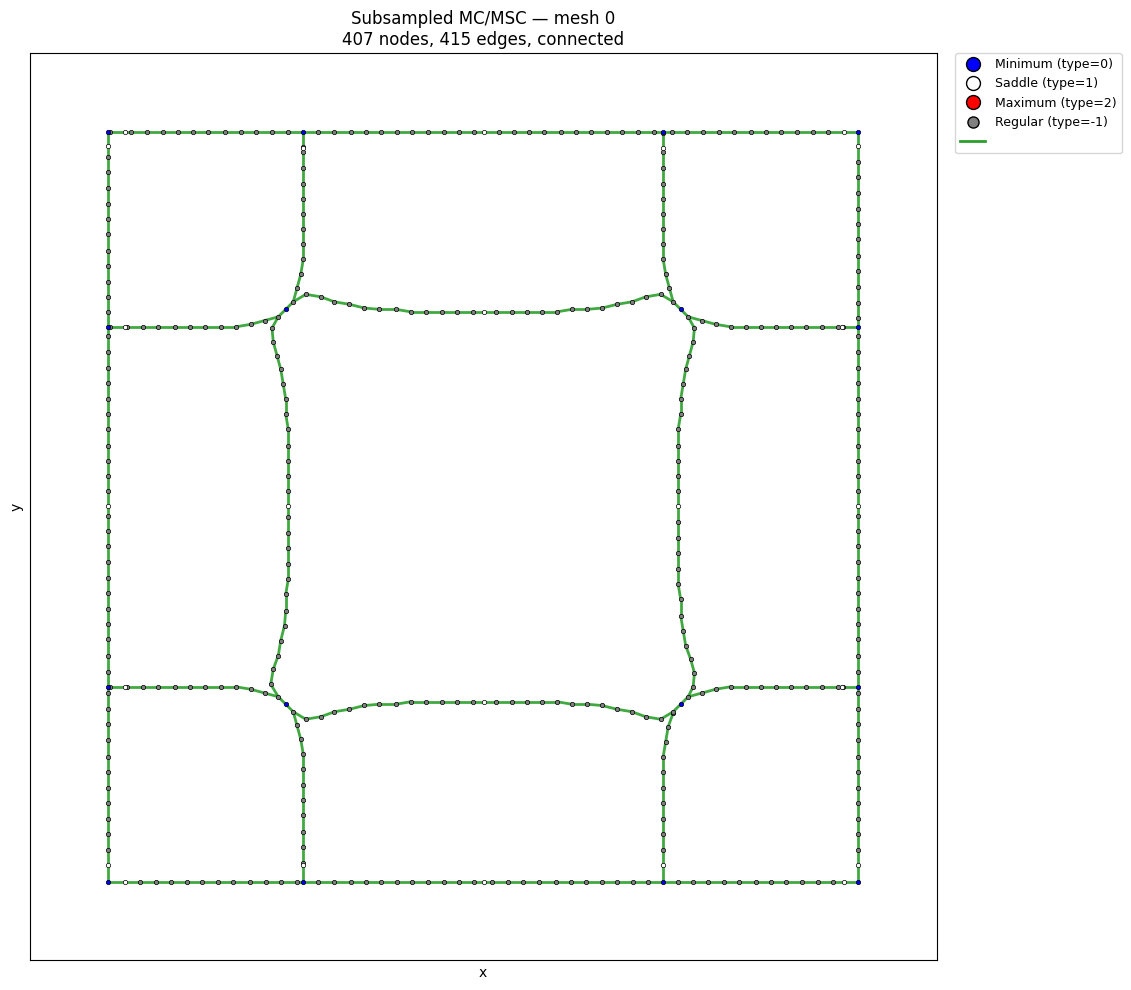

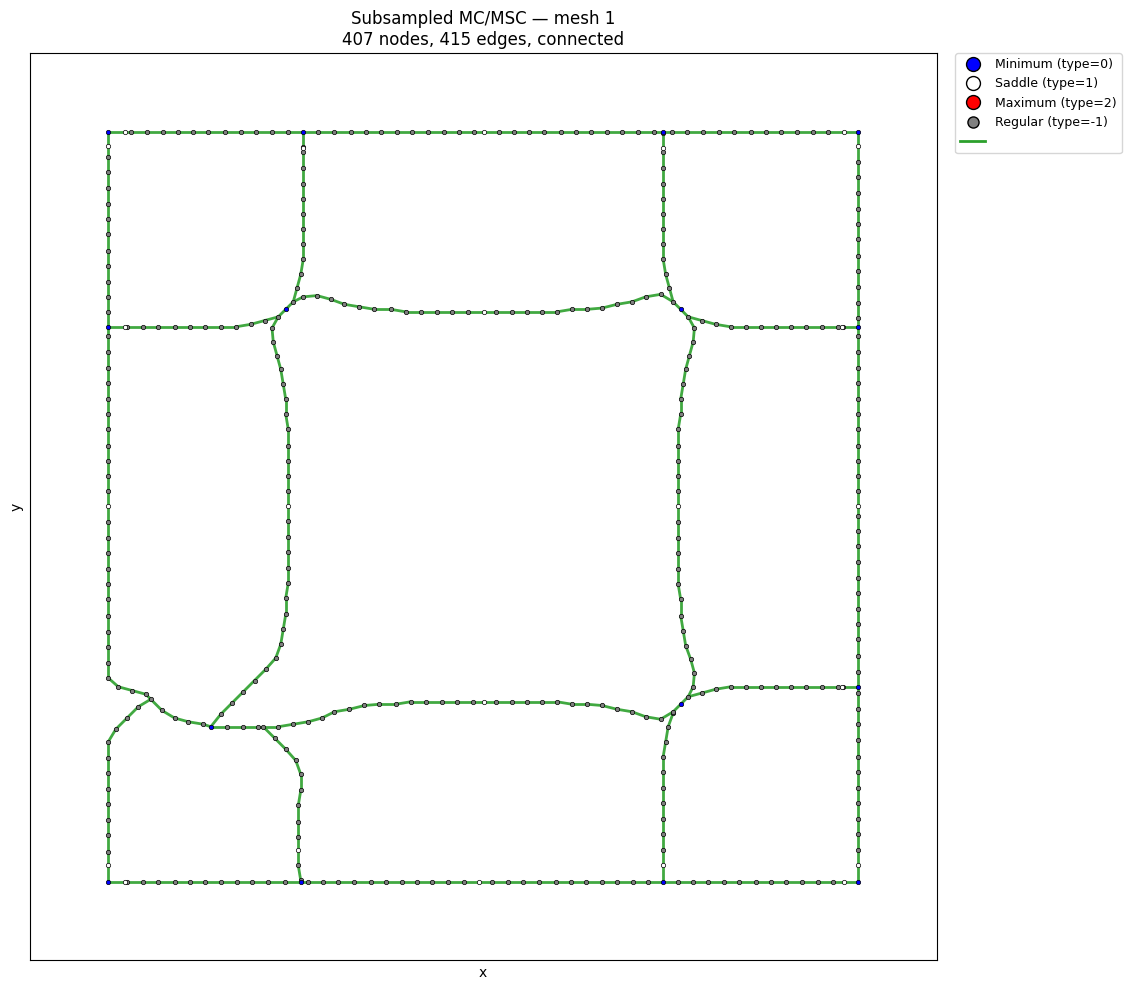

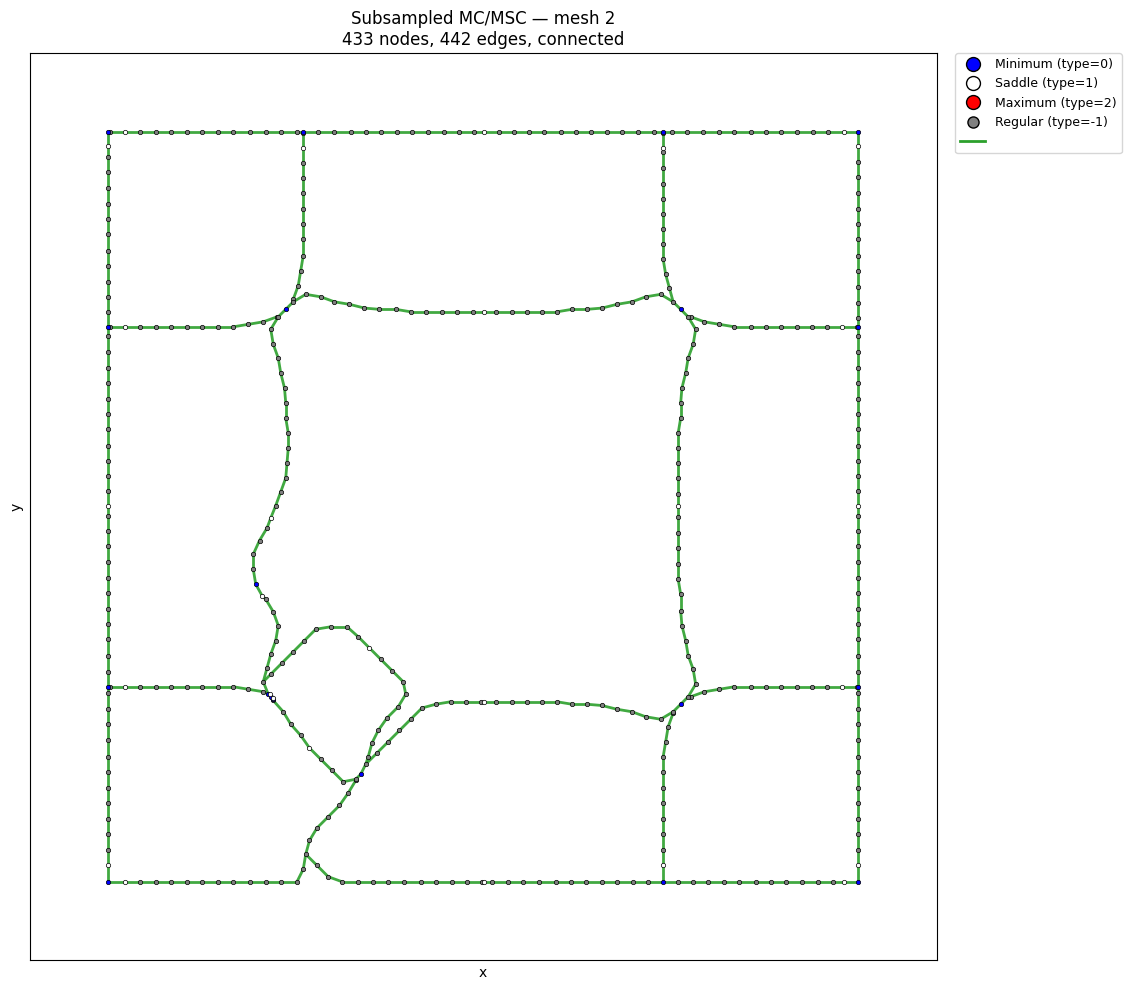

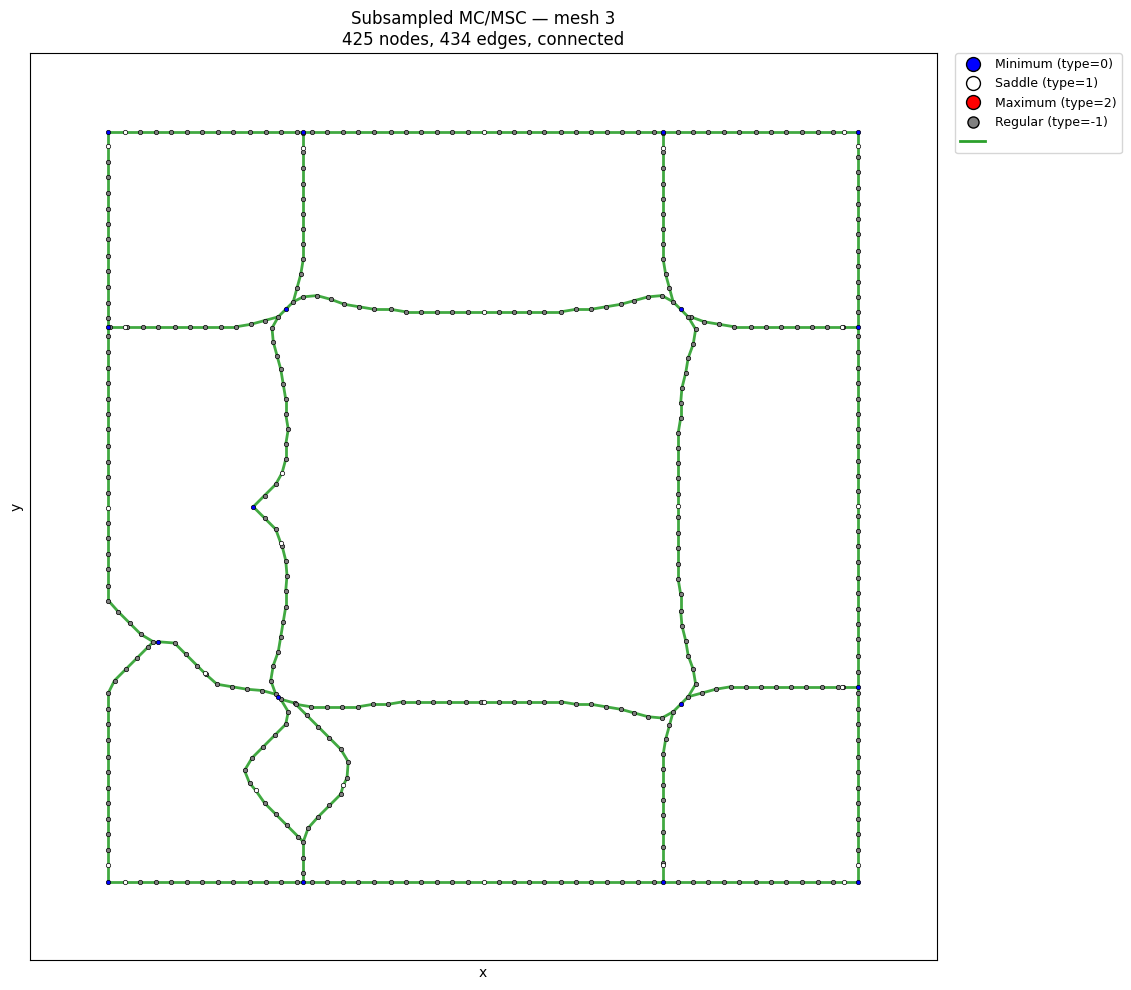

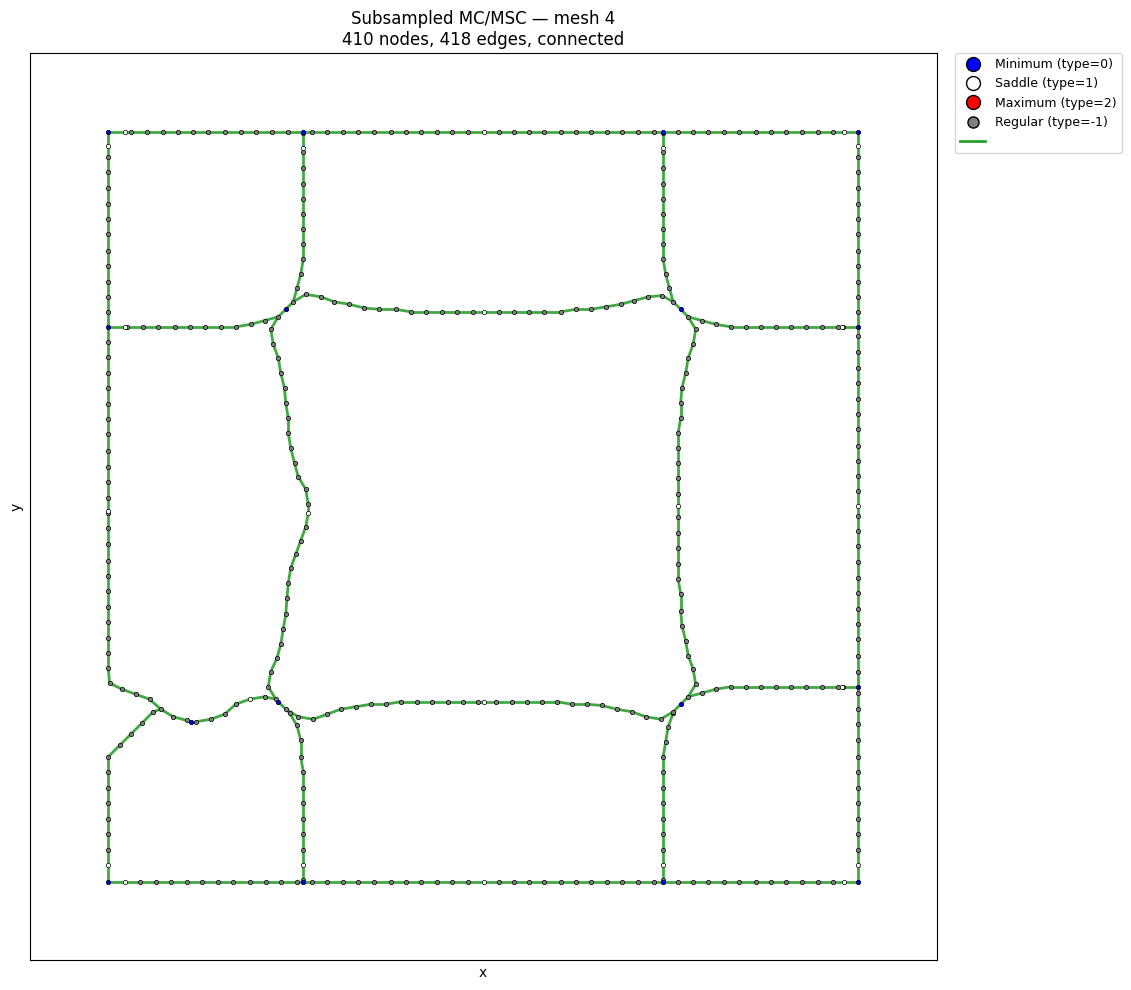

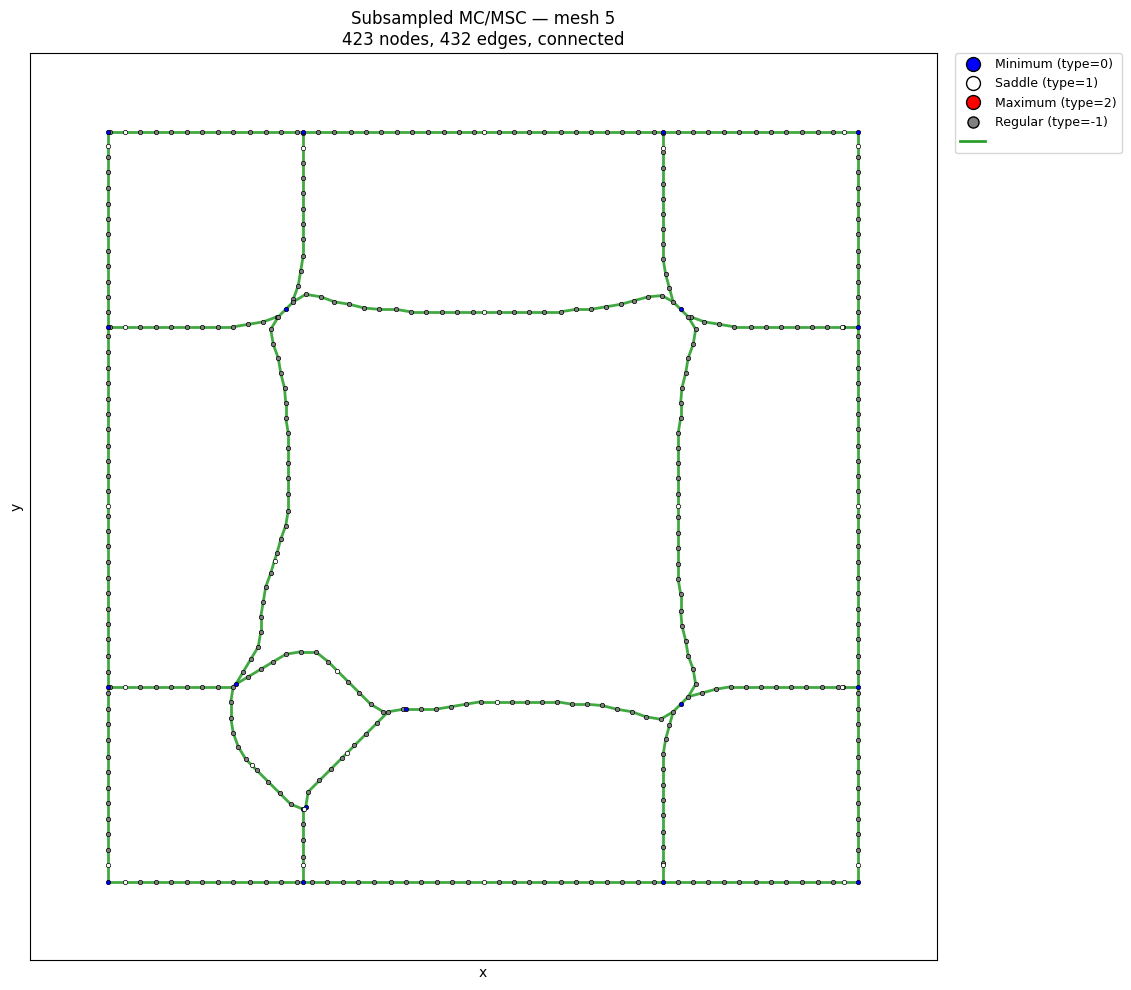

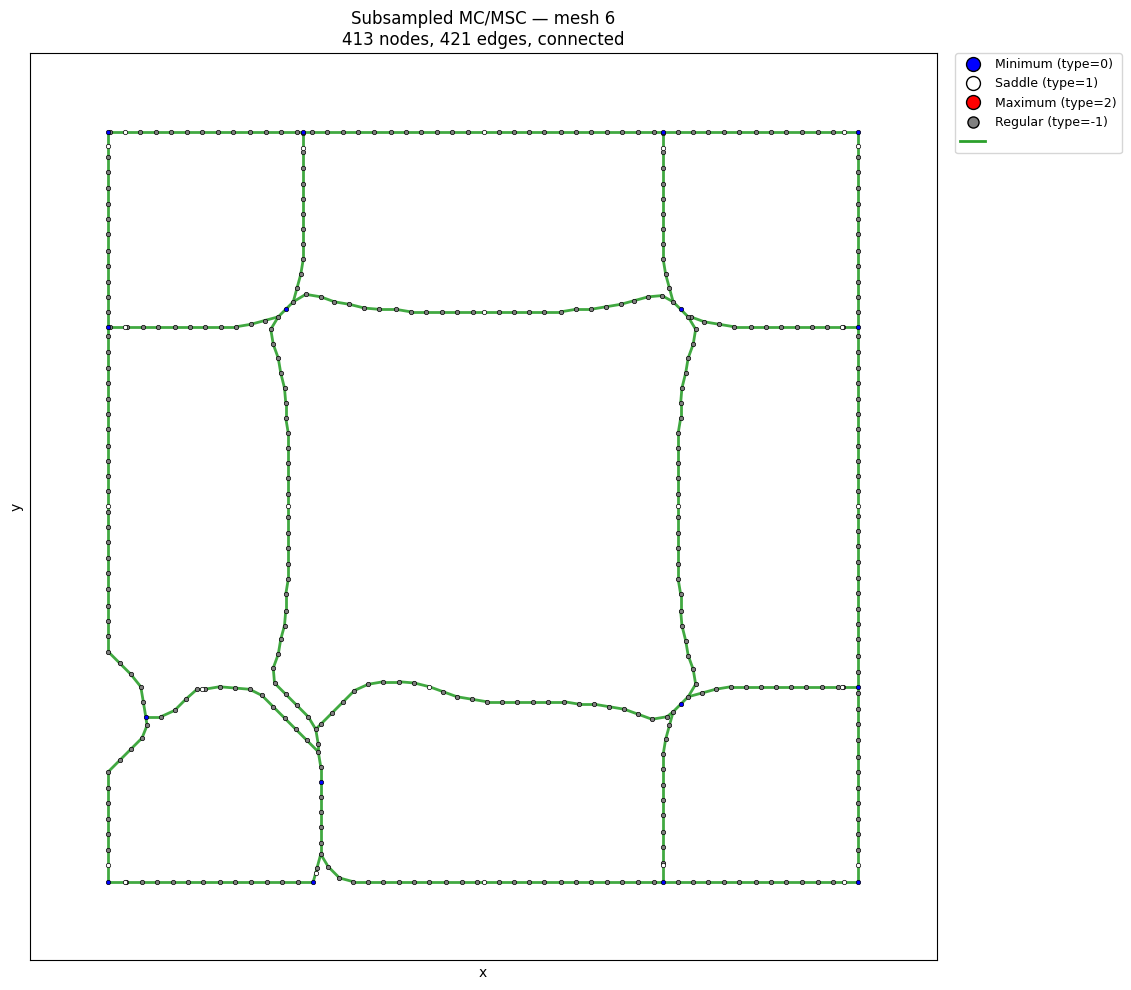

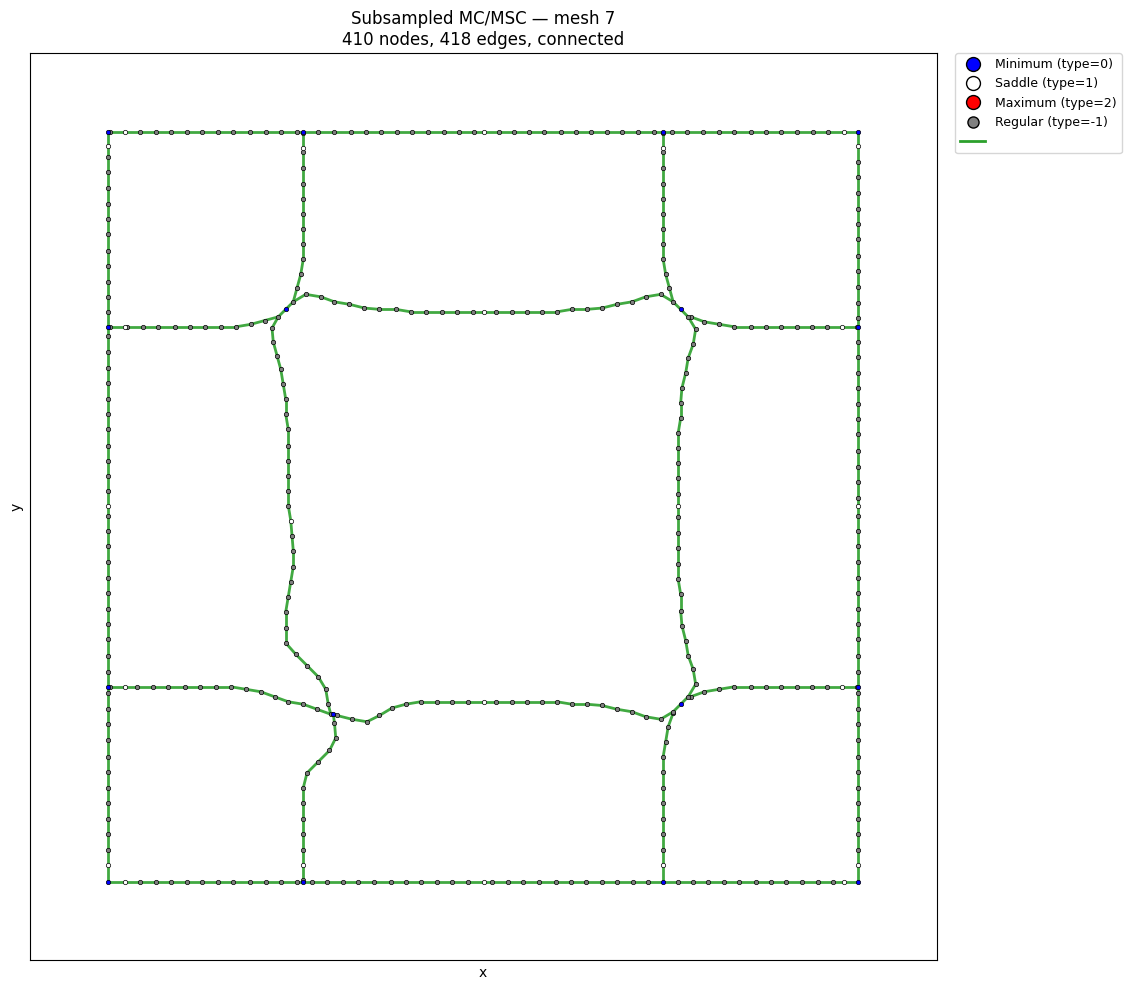

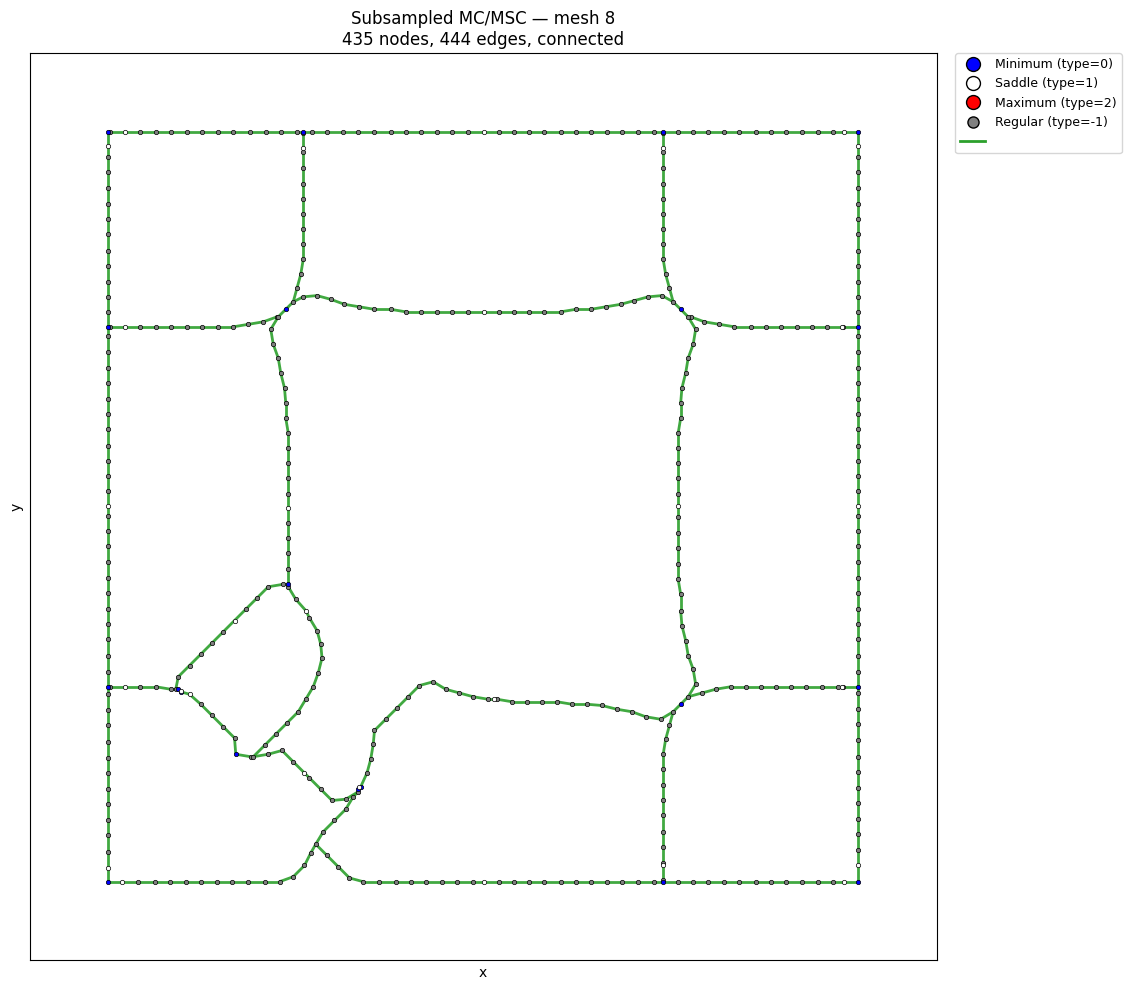

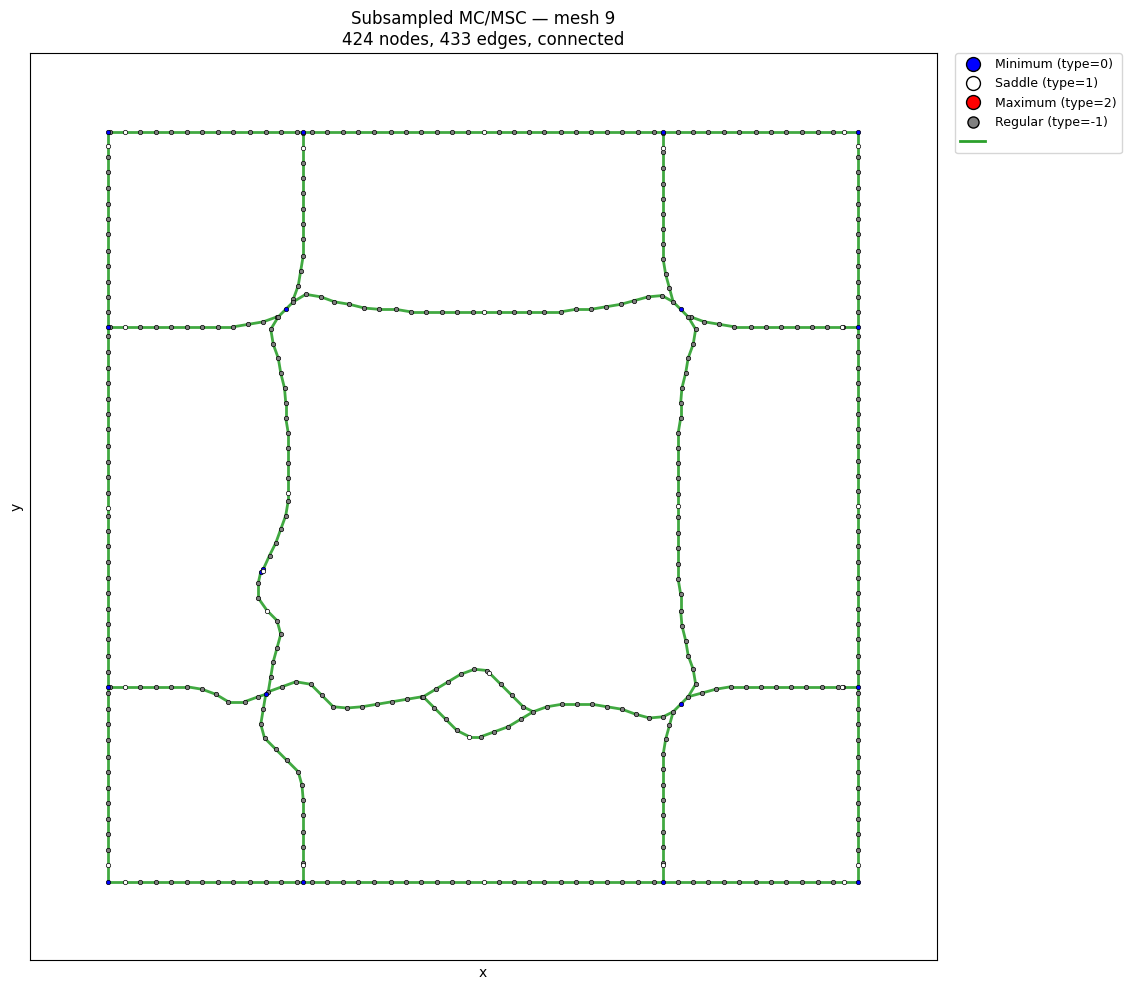

In [6]:
# Visualize processed (subsampled) MSC graphs in the (x, y) plane from file coordinates
draw_processed_msc_graphs(Gs, mesh_ids=mesh_ids, critical_size=10, regular_size=10)


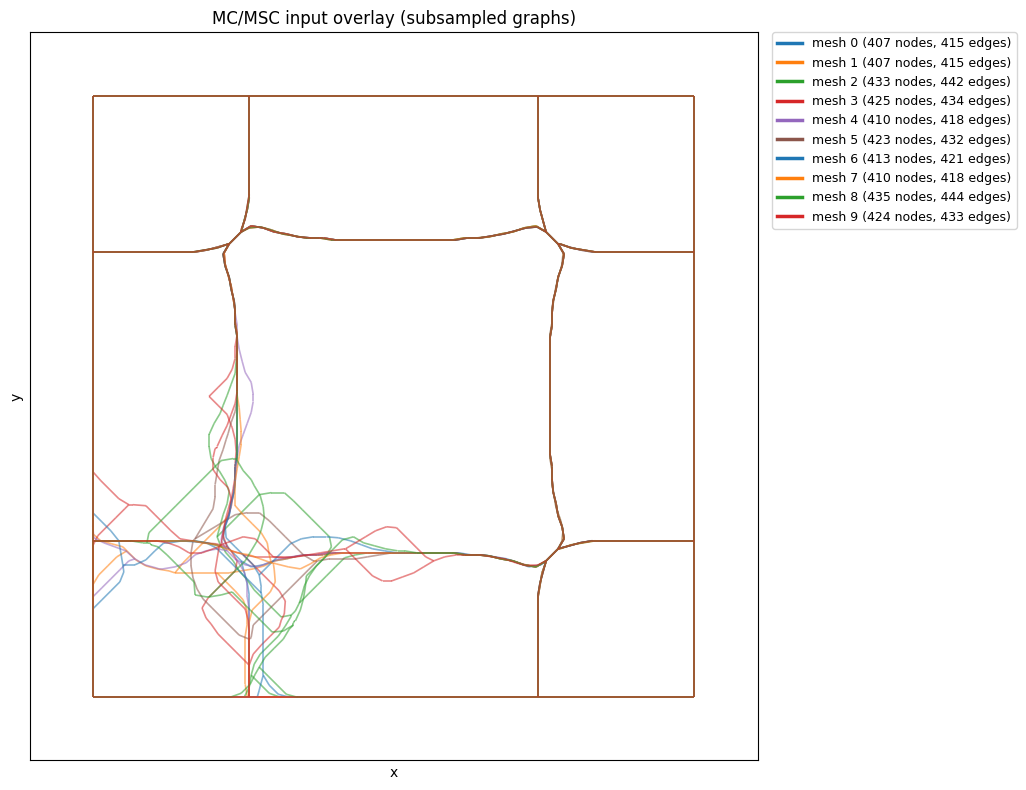

In [7]:
# Overlay all input MSC graphs in one (x, y) view — one edge color per mesh
draw_msc_graphs_overlay(Gs, mesh_ids=mesh_ids)


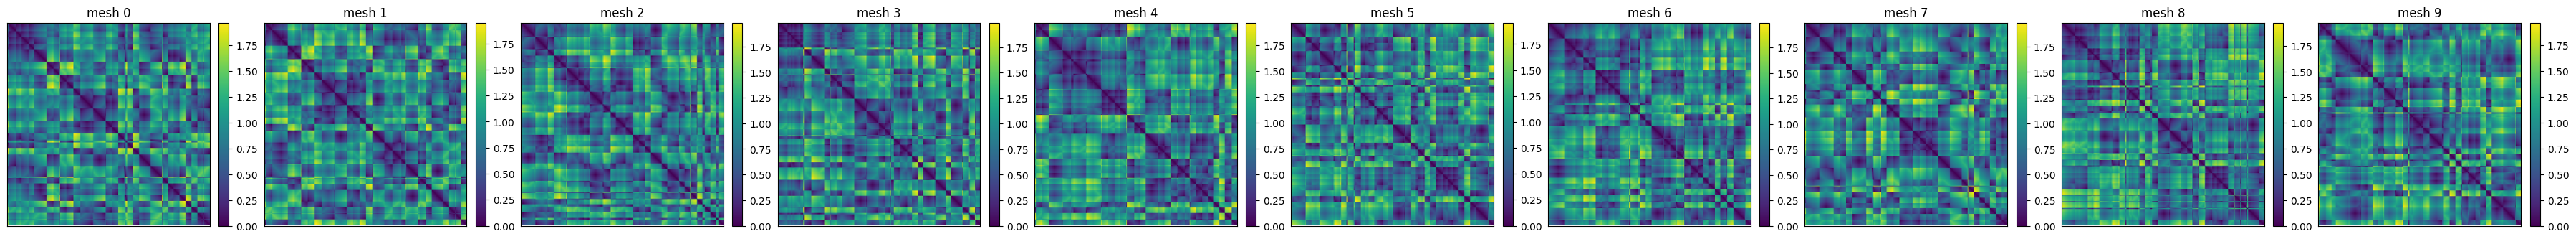

In [8]:
# Relation matrices (lib/graph_reader.relation_matrix — reload after edits)
import importlib
import lib.graph_reader as graph_reader

importlib.reload(graph_reader)
from lib.graph_reader import relation_matrix


def show_relation_matrices(graphs, kind="adjacency", cmap="viridis", sp_weighted=True):
    n = len(graphs)
    fig, axes = plt.subplots(1, n, figsize=(3.6 * n, 3.2), squeeze=False)
    for i, G in enumerate(graphs):
        C, _ = relation_matrix(G, kind=kind, sp_weighted=sp_weighted)
        ax = axes[0, i]
        im = ax.imshow(C, cmap=cmap)
        ax.set_title(f"mesh {mesh_ids[i]}")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()


show_relation_matrices(Gs, kind="shortestpath", sp_weighted=True)


In [9]:
### This only works for the synthetic data example.
### We select index=0 as the ground-truth of barycenter (which is a synthetic dataset without any added noises),
### and use it as the initialization for barycenters of other instances.
### In this case, we remove Gs[0] from the list of input.
### If seed_graph_id is None, the next cell picks the input with the minimum
### sum of PFGW distances to all other inputs.
if "synthetic" in str(MSC_DIR):
    seed_graph_id = 0
    exclude_seed = True
else:
    seed_graph_id = None
    exclude_seed = False

In [ ]:
# Measure-network initialization and seed selection
# Shortest-path structure uses summed 3D Euclidean edge lengths (sp_weighted=True).
# Rescale: C_scaled = C_raw / max_global_shortest_path (same as contour-tree FGW).
# If seed_graph_id is None, pick the input with minimum sum of PFGW distances
# to all other inputs (same PFGW hyperparameters as the barycenter).

# Node masses (p_i and p) use the discretized arc-length measure
#   mu(v) = ell(v) / sum_e length(e),  ell(v) = (1/2) sum_{e ni v} length(e)
# so every graph has total mass 1. Subdividing an edge only redistributes mass
# on that edge (sampling-invariant on the rest of the graph).
# This flag controls whether the seed graph is expanded to the size of the largest input graph.
# Expansion reinserts nodes dropped during subsampling; the input graphs themselves
# are left at their subsampled size even when one of them is chosen as the seed.
expand_to_largest = True

relation_kind = "shortestpath"
laplacian_base = "adjacency"
laplacian_normalization = "none"
tau = 1.0
sp_weighted = True  # sum 3D Euclidean edge lengths (MSC edges store Euclidean dist)
sp_affinity = "exp"
sp_sigma = None
relation_rescale = 1.0
relation_offset = 0.0

relation_rescale, relation_offset, rescale_diag = compute_relation_rescale(
    Gs, relation_kind, sp_weighted=sp_weighted
)
print("Rescale diagnostics:", rescale_diag)
print("relation_rescale:", relation_rescale)

use_partial = True
idx_list = list[int](range(len(Gs)))
n_graphs = len(idx_list) if not exclude_seed else len(idx_list) - 1
N_maxnode = max(Gs[idx].number_of_nodes() for idx in idx_list)
lambdas = np.ones(n_graphs, dtype=float) / n_graphs
max_iter = 200
bary_tol = 1e-6
random_state = 0
lambda_penalty = 1.00
alpha_fgw = 1 / N_maxnode
gw_restarts = 10
gw_seed_start = 0

print("lambda_penalty:", lambda_penalty, "alpha_fgw:", alpha_fgw)

# Node features for FGW: normalized (x, y, z) + normalized scalar + critical-point type
MSC_TYPE_ORDER = [0, 1, 2, -1]  # minimum, saddle, maximum, regular
type_to_idx = {t: i for i, t in enumerate(MSC_TYPE_ORDER)}
n_types = len(MSC_TYPE_ORDER)
type_scale = 1.0 / np.sqrt(2)   # type mismatch cost = 2 * (type_scale ** 2)

all_x, all_y, all_z = [], [], []
all_scalars = []
for idx in idx_list:
    G = Gs[idx]
    for n in G.nodes():
        all_x.append(G.nodes[n]["x"])
        all_y.append(G.nodes[n]["y"])
        all_z.append(G.nodes[n]["z"])
        all_scalars.append(node_height(G, n))

min_x, max_x = min(all_x), max(all_x)
min_y, max_y = min(all_y), max(all_y)
min_z, max_z = min(all_z), max(all_z)
domain_size = np.sqrt((max_x - min_x) ** 2 + (max_y - min_y) ** 2 + (max_z - min_z) ** 2)
domain_size = domain_size if domain_size > 0 else 1.0
min_scalar, max_scalar = min(all_scalars), max(all_scalars)
scalar_range = max_scalar - min_scalar
scalar_range = scalar_range if scalar_range > 0 else 1.0

def msc_fgw_features(G, nodes_idx):
    coords = np.array(
        [
            [
                (G.nodes[n]["x"] - min_x) / domain_size,
                (G.nodes[n]["y"] - min_y) / domain_size,
                (G.nodes[n]["z"] - min_z) / domain_size,
            ]
            for n in nodes_idx
        ],
        dtype=float,
    )
    scalars = np.array(
        [(node_height(G, n) - min_scalar) / scalar_range for n in nodes_idx],
        dtype=float,
    ).reshape(-1, 1)
    onehot = np.zeros((len(nodes_idx), n_types), dtype=float)
    for i, n in enumerate(nodes_idx):
        onehot[i, type_to_idx[msc_node_visual_type(G.nodes[n])]] = type_scale
    return np.column_stack([coords, scalars, onehot])


def msc_scaled_relation(G):
    C_idx, nodes_idx = relation_matrix(
        G,
        kind=relation_kind,
        laplacian_base=laplacian_base,
        laplacian_normalization=laplacian_normalization,
        tau=tau,
        sp_weighted=sp_weighted,
        sp_affinity=sp_affinity,
        sp_sigma=sp_sigma,
    )
    if relation_kind == "shortestpath":
        C_idx = apply_relation_scaling(
            C_idx, relation_kind, relation_rescale, relation_offset
        )
    return C_idx, nodes_idx


Ys = []
Cs = []
nodes_list = []
ps = []
for idx in idx_list:
    G = Gs[idx]
    C_idx, nodes_idx = msc_scaled_relation(G)
    Cs.append(C_idx)
    nodes_list.append(nodes_idx)
    Ys.append(msc_fgw_features(G, nodes_idx))
    ps.append(arc_length_node_measure(G, nodelist=nodes_idx, rescale_factor=N_maxnode))

for i, pe in enumerate(ps):
    print(
        f"  input {i} mesh {mesh_ids[i]}: n={len(pe)}, "
        f"arc-length mass sum={float(pe.sum()):.6f}, "
        f"min={float(pe.min()):.4g}, max={float(pe.max()):.4g}"
    )

# Seed: specified index, or the input with minimum sum of PFGW distances
# to all other measure networks (ties keep the earliest index).
if seed_graph_id is None:
    print("No seed specified; selecting the input with minimum PFGW sum to all others.")
    pair_lambda = 1000.0 if not use_partial else float(lambda_penalty)
    seed_graph_id, pfgw_pair_D, pfgw_pair_sums = select_seed_by_min_pfgw_sum(
        Cs,
        Ys,
        ps,
        lambda_penalty=pair_lambda,
        alpha_fgw=alpha_fgw,
        gw_restarts=gw_restarts,
        gw_seed_start=gw_seed_start,
        max_iter=max_iter,
        verbose=True,
    )
    print("PFGW pairwise costs (symmetric):")
    print(pfgw_pair_D)
    for i, s in enumerate(pfgw_pair_sums):
        mark = " <-- selected" if i == seed_graph_id else ""
        print(f"  idx {i} mesh {mesh_ids[i]}: sum={float(s):.6g}{mark}")
else:
    print(
        f"Using specified seed_graph_id={seed_graph_id} "
        f"(mesh {mesh_ids[seed_graph_id]})"
    )

N_center = Gs[seed_graph_id].number_of_nodes()
p = ps[seed_graph_id].copy()

# We put the index exclusion for seed network here.
# Because all previous computations involve all instances (initialization, measure network setups).
if exclude_seed:
    Cs_input = Cs[:seed_graph_id]
    Cs_input.extend(Cs[seed_graph_id + 1:])
    ps_input = ps[:seed_graph_id]
    ps_input.extend(ps[seed_graph_id + 1:])
    Ys_input = Ys[:seed_graph_id]
    Ys_input.extend(Ys[seed_graph_id + 1:])
    idx_list.remove(seed_graph_id)
else:
    Cs_input = Cs
    ps_input = ps
    Ys_input = Ys
    
init_C = Cs[seed_graph_id]
init_X = Ys[seed_graph_id]
init_p = p
if expand_to_largest and N_center < N_maxnode:
    seed_n_before = Gs[seed_graph_id].number_of_nodes()
    G_seed_expanded, expand_info = expand_sampled_graph_to_size(
        Gs[seed_graph_id],
        N_maxnode,
        source_graph=raw_graphs[seed_graph_id],
    )
    assert Gs[seed_graph_id].number_of_nodes() == seed_n_before, (
        "Seed expansion must not change the subsampled input graph size."
    )
    inserted = expand_info["inserted_nodes"]
    print(
        "Reinserted dropped seed nodes: "
        f"{expand_info['n_inserted']} "
        f"({expand_info['n_start']} -> {expand_info['n_end']}, "
        f"target {expand_info['n_target']}, "
        f"skipped_edges={expand_info['n_skipped_edges']})"
    )
    if inserted:
        ins_types = np.array(
            [
                msc_node_visual_type(raw_graphs[seed_graph_id].nodes[n])
                for n in inserted
            ],
            dtype=int,
        )
        print(
            "Inserted node types: "
            f"minima={int(np.sum(ins_types == 0))}, "
            f"saddles={int(np.sum(ins_types == 1))}, "
            f"maxima={int(np.sum(ins_types == 2))}, "
            f"regular={int(np.sum(ins_types == -1))}"
        )
    init_C, init_nodes = msc_scaled_relation(G_seed_expanded)
    init_X = msc_fgw_features(G_seed_expanded, init_nodes)
    init_p = arc_length_node_measure(G_seed_expanded, nodelist=init_nodes)
    N_center = int(init_C.shape[0])
    p = init_p

print(
    f"Seed network: idx={seed_graph_id}, mesh={mesh_ids[seed_graph_id]}, "
    f"n_nodes={Gs[seed_graph_id].number_of_nodes()}, N_center={N_center}, "
    f"exclude_seed={exclude_seed}, expand_to_largest={expand_to_largest}"
)


Rescale diagnostics: {'relation_kind': 'shortestpath', 'sp_weighted': True, 'max_dist_per_graph': [1.9648482500399709, 1.9493380089544483, 1.981929971601419, 1.9881822500399706, 1.9674903276200313, 1.9556344787289772, 1.9925454160790834, 1.9816253577567813, 1.9732935159717533, 1.9649593577567812], 'max_dist_global': 1.9925454160790834}
relation_rescale: 0.5018706183208576
lambda_penalty: 0.1 alpha_fgw: 0.00684931506849315
  input 0 mesh 0: n=407, arc-length mass sum=435.000000, min=0.1788, max=1.654
  input 1 mesh 1: n=407, arc-length mass sum=435.000000, min=0.1771, max=1.638
  input 2 mesh 2: n=433, arc-length mass sum=435.000000, min=0.08479, max=1.603
  input 3 mesh 3: n=425, arc-length mass sum=435.000000, min=0.1714, max=1.423
  input 4 mesh 4: n=410, arc-length mass sum=435.000000, min=0.1775, max=1.642
  input 5 mesh 5: n=423, arc-length mass sum=435.000000, min=0.1727, max=1.434
  input 6 mesh 6: n=413, arc-length mass sum=435.000000, min=0.1765, max=1.488
  input 7 mesh 7: n=

In [27]:
# Barycenter computation (partial FGW / PFGW)
# PFGW cost helper lives in lib.msc_barycenter_eval.pfgw_total_cost (shared with evaluation notebook)

def _pfgw_total_cost(C_tmp, X_tmp, p, Cs, Ys, ps, Lambda_list, lambdas, log_tmp, debug=False):
    return pfgw_total_cost(
        C_tmp,
        X_tmp,
        log_tmp["T"],
        Cs=Cs,
        Ys=Ys,
        p=p,
        ps=ps,
        Lambda_list=Lambda_list,
        lambdas=lambdas,
        alpha_fgw=alpha_fgw,
        debug=debug,
    )

if use_partial:
    Lambda_list = None if lambda_penalty is None else [lambda_penalty] * n_graphs
    C_center, X_center, log = pfgw_barycenters(
        N=N_center,
        Ys=Ys_input,
        Cs=Cs_input,
        ps=ps_input,
        p=init_p,
        Lambda_list=Lambda_list,
        lambdas=lambdas,
        alpha=alpha_fgw,
        max_iter=max_iter,
        tol=bary_tol,
        log=True,
        init_C=init_C,
        init_X=init_X,
        random_state=random_state,
        gw_restarts=gw_restarts,
        gw_seed_start=gw_seed_start,
        debug=True,
    )
else:
    Lambda_list = [1000] * n_graphs
    C_center, X_center, log = pfgw_barycenters(
        N=N_center,
        Ys=Ys_input,
        Cs=Cs_input,
        ps=ps_input,
        p=init_p,
        Lambda_list=Lambda_list,
        lambdas=lambdas,
        alpha=alpha_fgw,
        max_iter=max_iter,
        tol=bary_tol,
        log=True,
        init_C=init_C,
        init_X=init_X,
        random_state=random_state,
        gw_restarts=gw_restarts,
        gw_seed_start=gw_seed_start,
        debug=True,
    )

print("relation_kind:", relation_kind)
print("Barycenter matrix shape:", C_center.shape)
print("Barycenter feature shape:", X_center.shape)
if relation_kind == "shortestpath":
    C_center = np.nan_to_num(C_center, nan=np.inf, posinf=np.inf)
elif relation_kind == "adjacency":
    C_center = np.nan_to_num(C_center, nan=0.0)

print("PFGW Cost:", _pfgw_total_cost(C_center, X_center, init_p, Cs_input, Ys_input, ps_input, Lambda_list, lambdas, log, debug=True))


pfgw barycenter starts...
iter 0 err 5.750017932104919
iter 1 err 1.135818324657896
iter 2 err 0.9394302601297677
iter 3 err 0.8627006699749471
iter 4 err 0.35718085713335285
iter 5 err 0.15290358107110102
iter 6 err 0.1005053498833373
iter 7 err 0.07903333176463002
iter 8 err 0.02333084092439492
iter 9 err 3.723827897959257e-15
relation_kind: shortestpath
Barycenter matrix shape: (435, 435)
Barycenter feature shape: (435, 8)
d, penalty: 0.00021631184347034574 18922.400000000107
d, penalty: 0.00014157605603518715 18922.4000000001
d, penalty: 0.00010276384011324238 18922.400000000107
d, penalty: 0.00011536702705615827 18922.40000000015
d, penalty: 0.00012718472102886036 18922.40000000015
d, penalty: 0.00016515355017944014 18922.40000000014
d, penalty: 9.223127960499656e-05 18922.40000000013
d, penalty: 0.00015065599162298774 18922.400000000165
d, penalty: 0.00014977910117520103 18922.400000000107
PFGW Cost: 18922.400140113838


In [28]:
print(log['T'][1])

[[0.00123338 0.         0.         ... 0.         0.         0.        ]
 [0.         0.00195288 0.         ... 0.         0.         0.        ]
 [0.         0.         0.00195288 ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]


Barycenter MST: 435 nodes, 434 edges
Complete barycenter graph: 435 nodes, 94358 edges (94358 candidates)
unscaled weight - euclidean (MST edges): [ 6.93889390e-18  6.93889390e-18  2.08166817e-17  0.00000000e+00
  1.73472348e-17  3.46944695e-18  6.94723514e-03  1.54495401e-02
  1.55707529e-02  4.11645595e-03  1.35174611e-02 -8.02309608e-17
 -8.06646416e-17  1.29256511e-04  1.29256511e-04  1.06305997e-02
  1.62764216e-02  7.68238282e-04  1.03553007e-04  1.52443765e-05
  1.03553007e-04  7.33838889e-05  7.33838889e-05  1.47458128e-02
  1.16419680e-03  2.28918314e-02  7.15274758e-03  2.51534904e-17
  1.96170146e-03  6.00417741e-05  6.00417741e-05  6.00417741e-05
  6.00417741e-05  1.86463479e-04  1.86463479e-04  4.65804963e-03
  7.18025972e-03  2.99669488e-03  2.27677561e-02  6.03978099e-03
  3.74683482e-05  1.06741187e-02  7.30746274e-05  1.06053843e-03
  5.63167570e-04  3.22045969e-03  7.62468236e-04  4.07416141e-04
  3.05594960e-04  3.05594960e-04  3.05594960e-04  8.36139708e-04
  3.1980

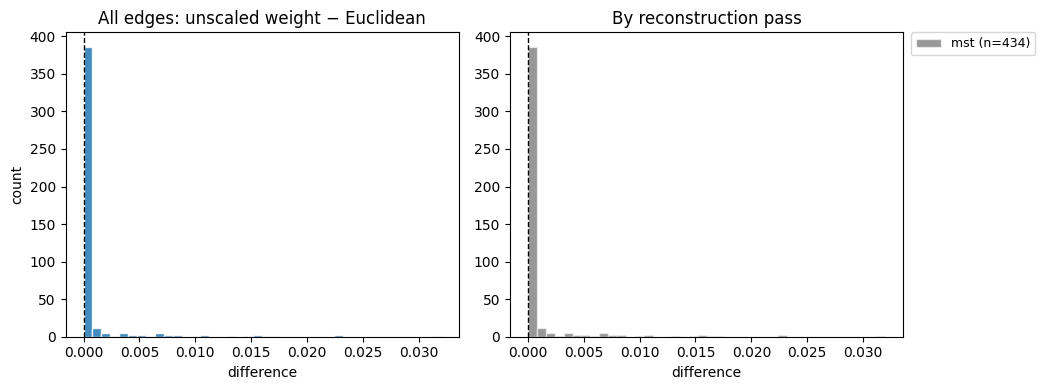

relation unscale: kind=shortestpath, sp_weighted=True, rescale=0.501871, offset=0
unscaled weight − euclidean: n=434, min=-8.91648e-16, max=0.031981, mean=0.000799347, std=0.00314611, below_eucl=0
Top |difference| edges:
  (41, 42) pass=mst weight_scaled=0.0161432 weight_raw=0.0321661 eucl=0.000185111 diff=0.031981
  (18, 19) pass=mst weight_scaled=0.027074 weight_raw=0.0539461 eucl=0.0310543 diff=0.0228918
  (29, 43) pass=mst weight_scaled=0.0273364 weight_raw=0.0544691 eucl=0.0317013 diff=0.0227678
  (53, 236) pass=mst weight_scaled=0.0392666 weight_raw=0.0782405 eucl=0.0608456 diff=0.0173949
  (10, 12) pass=mst weight_scaled=0.0373181 weight_raw=0.074358 eucl=0.0580815 diff=0.0162764


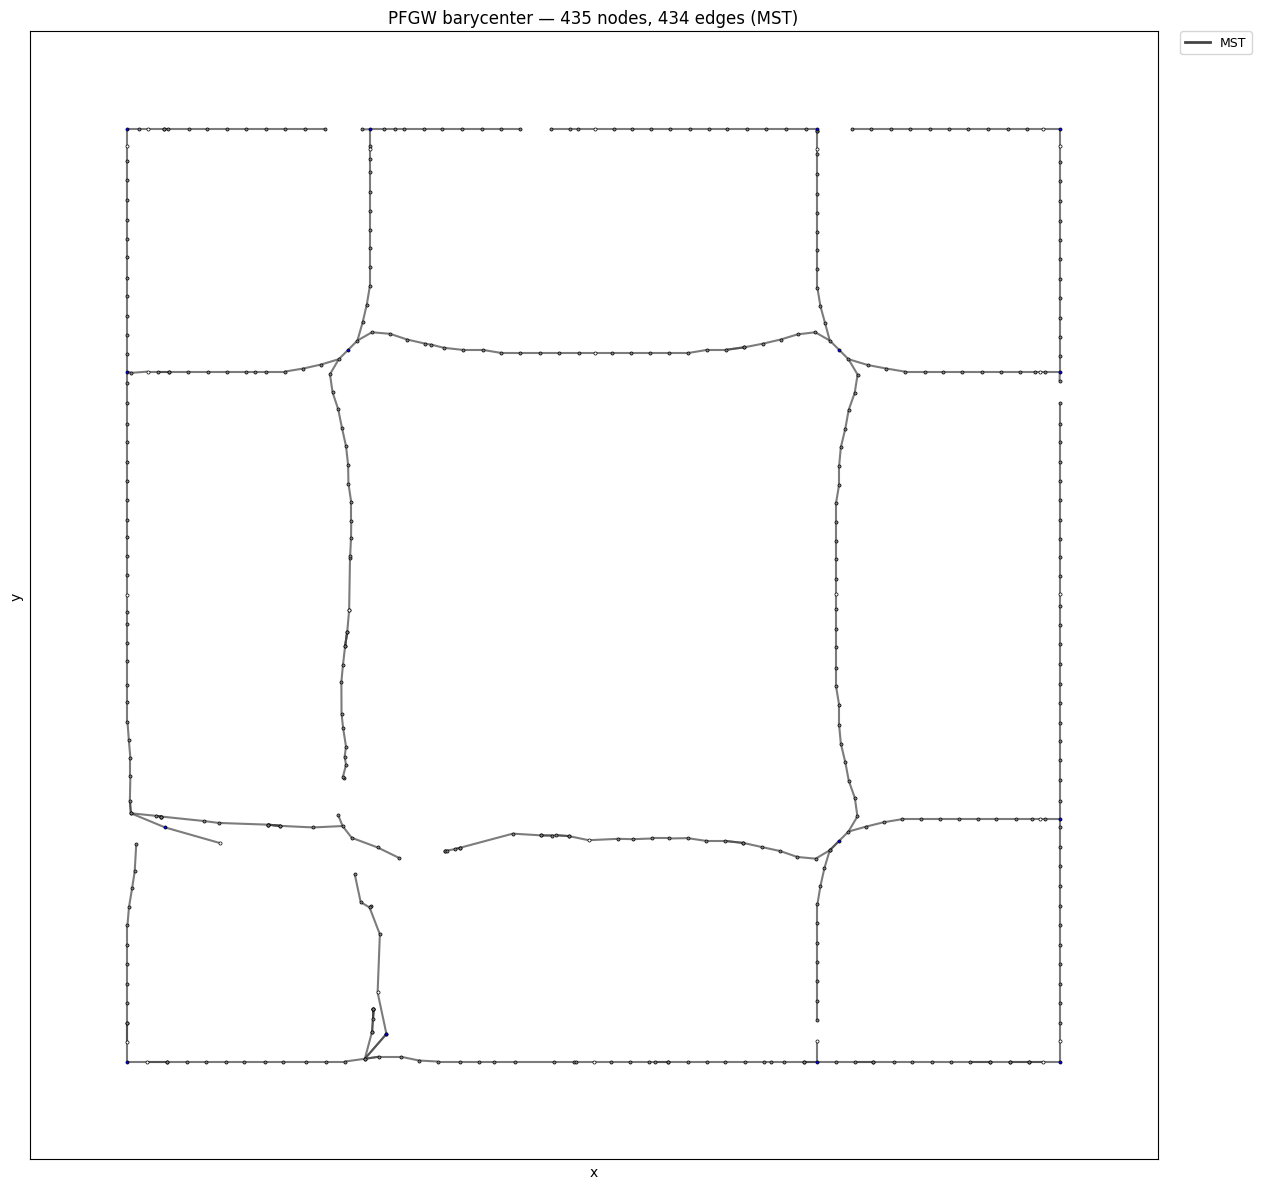

Saved barycenter bundle -> C:\Users\mingz\desktop\MSCBarycenter\results\barycenters\synthetic_latest (exclude_seed=True, seed_graph_id=0, n_inputs=9)


In [29]:
# Reconstruct MST barycenter, build complete (pre-threshold) graph, and save bundle
importlib.reload(barycenter_io)
from lib.barycenter_io import save_barycenter_bundle

G_center = reconstruct_msc_barycenter_mst_graph(
    C_center,
    X_center,
    min_x=min_x,
    min_y=min_y,
    min_z=min_z,
    domain_size=domain_size,
    scalar_min=min_scalar,
    scalar_range=scalar_range,
    msc_type_order=MSC_TYPE_ORDER,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    sp_weighted=sp_weighted,
)

print(
    f"Barycenter MST: {G_center.number_of_nodes()} nodes, {G_center.number_of_edges()} edges"
)

# Complete (unthresholded) barycenter graph: all finite positive C_center edges
G_complete, complete_candidates = build_complete_barycenter_graph(
    C_center,
    X_center,
    min_x=min_x,
    min_y=min_y,
    min_z=min_z,
    domain_size=domain_size,
    scalar_min=min_scalar,
    scalar_range=scalar_range,
    msc_type_order=MSC_TYPE_ORDER,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    sp_weighted=sp_weighted,
)
print(
    f"Complete barycenter graph: {G_complete.number_of_nodes()} nodes, "
    f"{G_complete.number_of_edges()} edges "
    f"({len(complete_candidates)} candidates)"
)

weight_eucl_diffs = msc_barycenter_weight_euclidean_differences(
    G_center,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    relation_kind=relation_kind,
)
print("unscaled weight - euclidean (MST edges):", weight_eucl_diffs)
plot_msc_barycenter_weight_euclidean_debug(
    G_center,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    relation_kind=relation_kind,
    bins=40,
    by_pass=True,
)
draw_msc_barycenter_graph(G_center)

# --- persist fully loadable bundle for evaluation notebook ---
# Cs_input / Ys_input / ps_input are the PFGW barycenter inputs (seed omitted when
# exclude_seed). The seed itself is stored under seed/ so evaluation can score
# an out-of-set baseline without mixing it into the input family.
BARYCENTER_OUTDIR = default_barycenter_outdir(run_name=f"{DATA_KEYWORD}_latest")
nodes_list_input = (
    nodes_list[:seed_graph_id] + nodes_list[seed_graph_id + 1 :]
    if exclude_seed
    else nodes_list
)
save_kwargs = dict(
    C_center=C_center,
    X_center=X_center,
    p=init_p,
    Cs=Cs_input,
    Ys=Ys_input,
    ps=ps_input,
    Ts=log["T"],
    lambdas=lambdas,
    nodes_list=nodes_list_input,
    Gs=[Gs[i] for i in idx_list],
    G_mst=G_center,
    G_complete=G_complete,
    mesh_ids=[mesh_ids[i] for i in idx_list],
    exclude_seed=bool(exclude_seed),
    seed_graph_id=int(seed_graph_id),
    meta={
        "min_x": min_x,
        "max_x": max_x,
        "min_y": min_y,
        "max_y": max_y,
        "min_z": min_z,
        "max_z": max_z,
        "domain_size": domain_size,
        "min_scalar": min_scalar,
        "max_scalar": max_scalar,
        "scalar_range": scalar_range,
        "MSC_TYPE_ORDER": list(MSC_TYPE_ORDER),
        "type_scale": float(type_scale),
        "relation_kind": relation_kind,
        "relation_rescale": float(relation_rescale),
        "relation_offset": float(relation_offset),
        "sp_weighted": bool(sp_weighted),
        "laplacian_base": laplacian_base,
        "laplacian_normalization": laplacian_normalization,
        "tau": float(tau),
        "sp_affinity": sp_affinity,
        "sp_sigma": sp_sigma,
        "alpha_fgw": float(alpha_fgw),
        "lambda_penalty": None if lambda_penalty is None else float(lambda_penalty),
        "Lambda_list": list(Lambda_list) if Lambda_list is not None else None,
        "gw_restarts": int(gw_restarts),
        "gw_seed_start": int(gw_seed_start),
        "max_iter": int(max_iter),
        "node_measure": "arc_length",
        "balanced_distribution": True,
        "expand_to_largest": bool(expand_to_largest),
        "N_center": int(N_center),
        "MSC_DIR": str(MSC_DIR),
    },
    build_complete_if_missing=False,
)
if exclude_seed:
    save_kwargs.update(
        C_seed=Cs[seed_graph_id],
        Y_seed=Ys[seed_graph_id],
        p_seed=ps[seed_graph_id],
        G_seed=Gs[seed_graph_id],
        seed_nodes=nodes_list[seed_graph_id],
        seed_mesh_id=mesh_ids[seed_graph_id],
    )
save_barycenter_bundle(BARYCENTER_OUTDIR, **save_kwargs)
print(
    f"Saved barycenter bundle -> {BARYCENTER_OUTDIR.resolve()} "
    f"(exclude_seed={exclude_seed}, seed_graph_id={seed_graph_id}, "
    f"n_inputs={len(Cs_input)})"
)


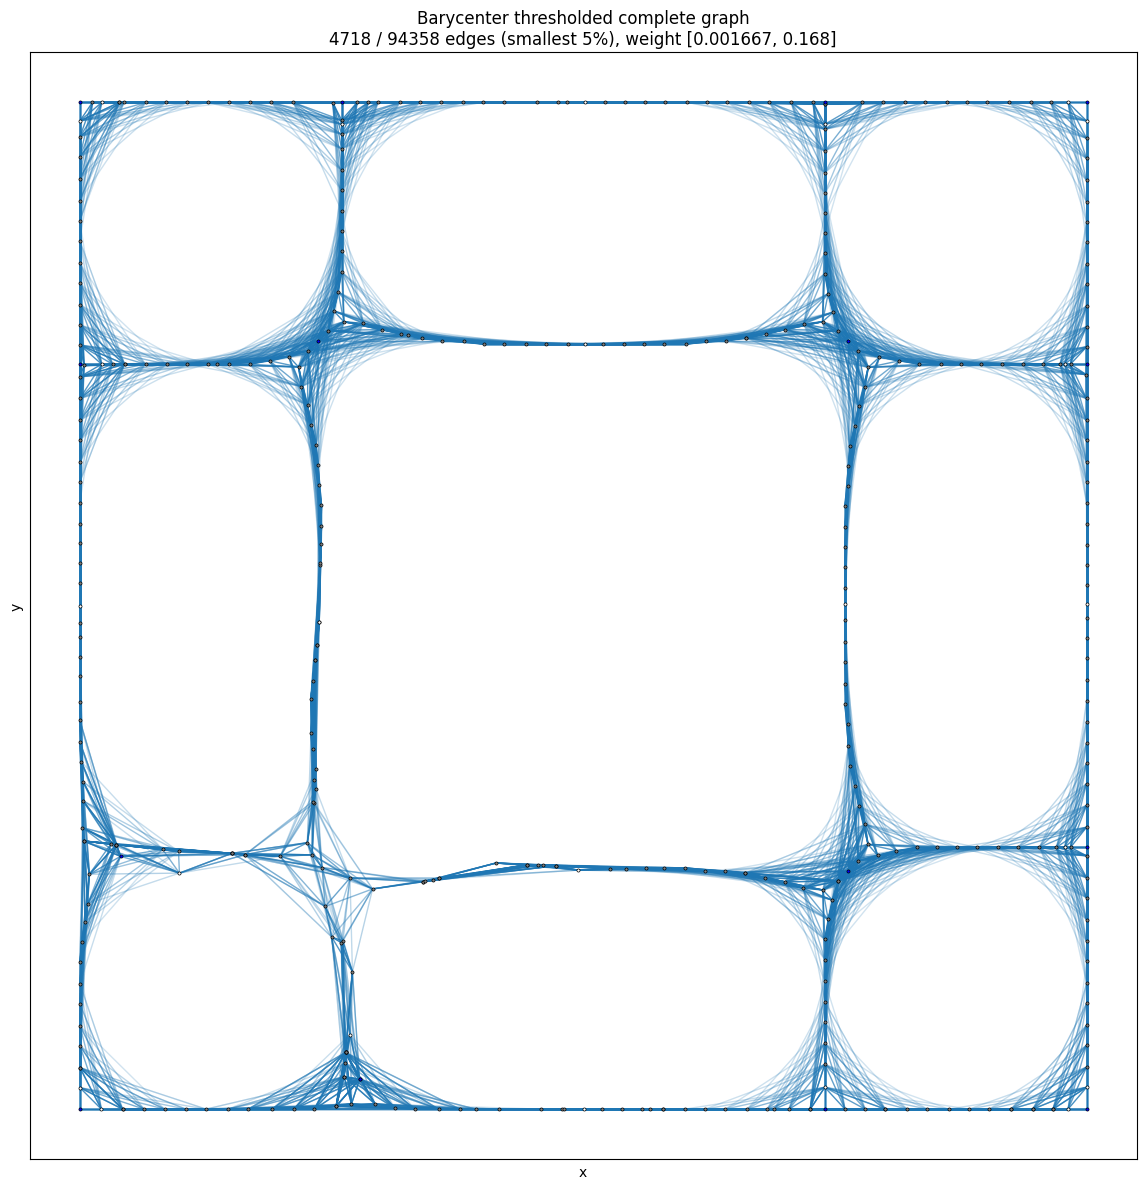

Kept 4718 edges (5% of 94358 candidates); alpha in [0.2, 1.0] by weight


[(0.0016669999999999738, 145, 146),
 (0.0016669999999999738, 146, 381),
 (0.002222222222222225, 321, 322),
 (0.002229918771703371, 54, 55),
 (0.002290614236454257, 8, 408),
 (0.0022906142364542575, 7, 408),
 (0.0023570226039551596, 20, 21),
 (0.004475091144888625, 14, 15),
 (0.004814888888888888, 130, 131),
 (0.0048148888888888885, 130, 420),
 (0.0050000000000000044, 208, 209),
 (0.005370666666666664, 237, 238),
 (0.005740999999999984, 171, 406),
 (0.005740999999999984, 196, 394),
 (0.006481666666666655, 170, 171),
 (0.006642363483419168, 9, 11),
 (0.0066423634834191685, 9, 10),
 (0.006758606767999197, 337, 407),
 (0.00688166449991289, 50, 52),
 (0.006881664499912891, 51, 52),
 (0.006881664499912891, 52, 416),
 (0.00722233333333333, 95, 431),
 (0.00722233333333333, 101, 433),
 (0.008151171487461781, 31, 32),
 (0.008333000000000033, 368, 369),
 (0.008333333333333338, 195, 196),
 (0.00888866666666669, 106, 121),
 (0.0088888888888889, 116, 117),
 (0.009629666666666672, 119, 120),
 (0.0096

In [30]:
# Alternative barycenter view: keep smallest-weight X% of complete-graph edges

EDGE_FRACTION_PCT = 5.0
ALPHA_MIN = 0.2
ALPHA_MAX = 1.0

_pos_recon = {
    n: np.array([G_center.nodes[n]["x"], G_center.nodes[n]["y"]], dtype=float)
    for n in G_center.nodes()
}

draw_barycenter_thresholded_complete(
    C_center,
    X_center,
    min_x=min_x,
    min_y=min_y,
    min_z=min_z,
    domain_size=domain_size,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    edge_fraction_pct=EDGE_FRACTION_PCT,
    alpha_min=ALPHA_MIN,
    alpha_max=ALPHA_MAX,
    pos=_pos_recon,
    node_attr_graph=G_center,
)


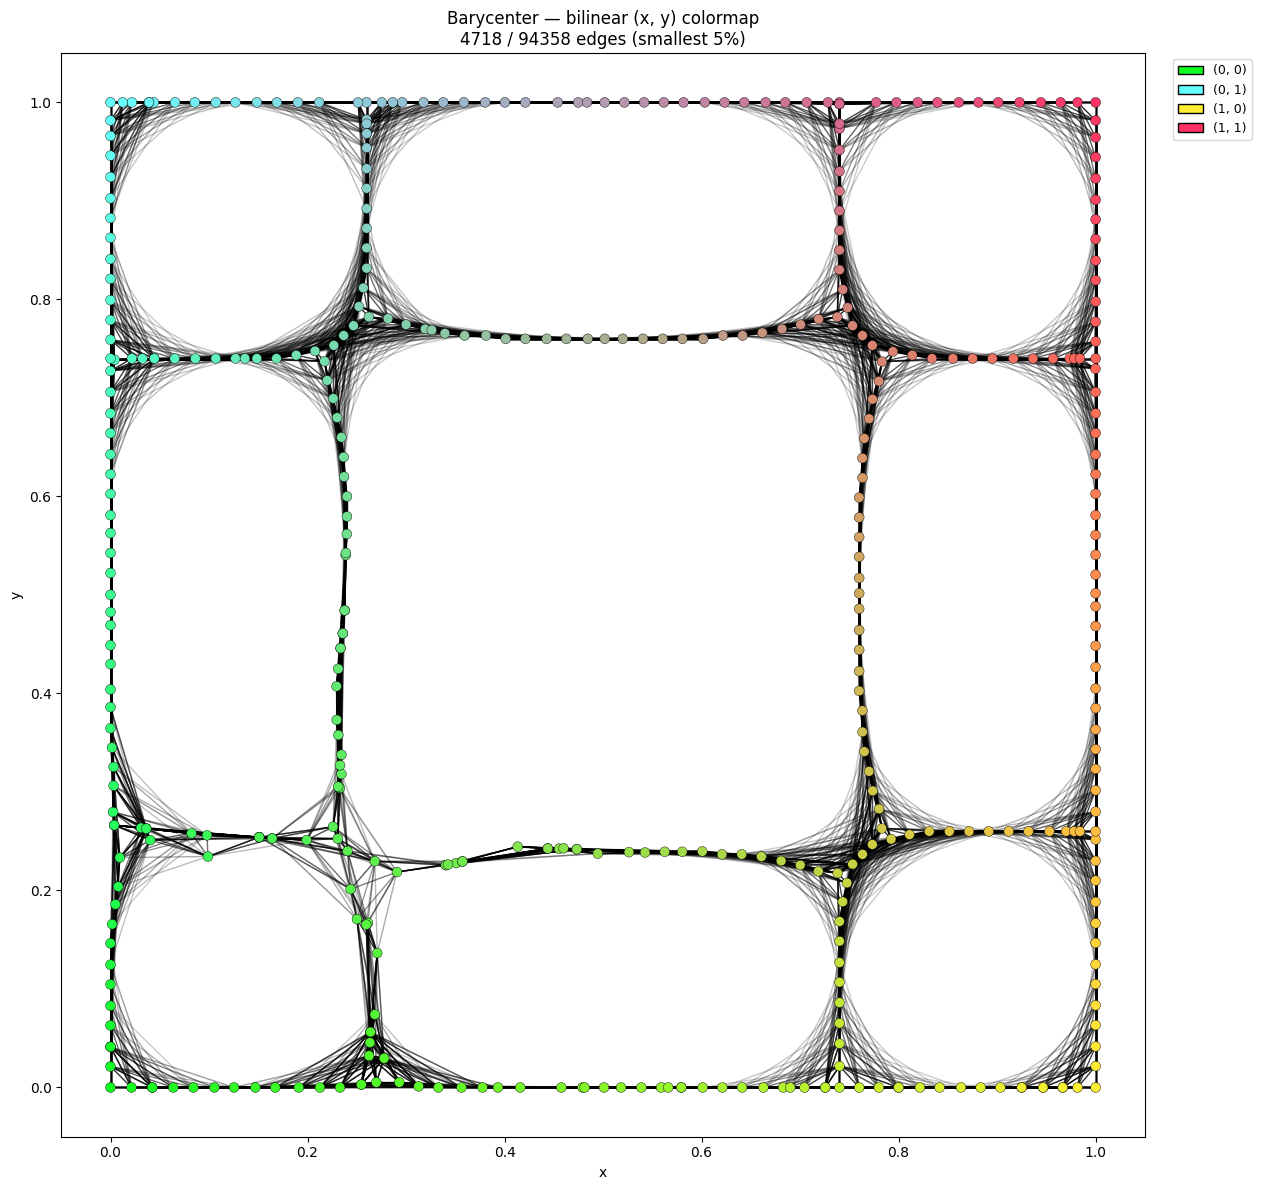

Colormap mode: bilinear; kept 4718 edges (5% of 94358 candidates)


In [31]:
# Color transfer (1): barycenter colormap — bilinear (x, y) or categorical (node id)

BARYCENTER_COLOR_MODE = "bilinear"  # "bilinear" | "categorical"
BARYCENTER_CORNER_COLORS = DEFAULT_CORNER_COLORS
BARYCENTER_CATEGORICAL_CMAP = "tab20"
BARYCENTER_CATEGORICAL_MAX_COLORS = 20

_pos_barycenter = {
    n: np.array([G_center.nodes[n]["x"], G_center.nodes[n]["y"]], dtype=float)
    for n in G_center.nodes()
}

barycenter_node_colors = compute_barycenter_node_colors(
    BARYCENTER_COLOR_MODE,
    X_center.shape[0],
    _pos_barycenter,
    min_x=min_x,
    max_x=max_x,
    min_y=min_y,
    max_y=max_y,
    corner_colors=BARYCENTER_CORNER_COLORS,
    categorical_cmap=BARYCENTER_CATEGORICAL_CMAP,
    categorical_max_colors=BARYCENTER_CATEGORICAL_MAX_COLORS,
)

barycenter_node_colors = draw_barycenter_colormap(
    C_center,
    X_center,
    barycenter_node_colors,
    color_mode=BARYCENTER_COLOR_MODE,
    min_x=min_x,
    min_y=min_y,
    max_x=max_x,
    max_y=max_y,
    min_z=min_z,
    domain_size=domain_size,
    corner_colors=BARYCENTER_CORNER_COLORS,
    categorical_cmap=BARYCENTER_CATEGORICAL_CMAP,
    categorical_max_colors=BARYCENTER_CATEGORICAL_MAX_COLORS,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    edge_fraction_pct=EDGE_FRACTION_PCT,
    alpha_min=ALPHA_MIN,
    alpha_max=ALPHA_MAX,
    node_size=50,
    pos=_pos_barycenter,
)

barycenter_bilinear_colors = barycenter_node_colors  # alias


Graph 0: coupling threshold = 5.64828e-06; pie nodes = 43 / 407
Graph 1: coupling threshold = 5.30912e-06; pie nodes = 42 / 433
Graph 2: coupling threshold = 5.40906e-06; pie nodes = 46 / 425
Graph 3: coupling threshold = 5.60695e-06; pie nodes = 45 / 410
Graph 4: coupling threshold = 5.43463e-06; pie nodes = 43 / 423
Graph 5: coupling threshold = 5.56622e-06; pie nodes = 43 / 413
Graph 6: coupling threshold = 5.60695e-06; pie nodes = 44 / 410
Graph 7: coupling threshold = 5.28471e-06; pie nodes = 44 / 435
Graph 8: coupling threshold = 5.42182e-06; pie nodes = 44 / 424


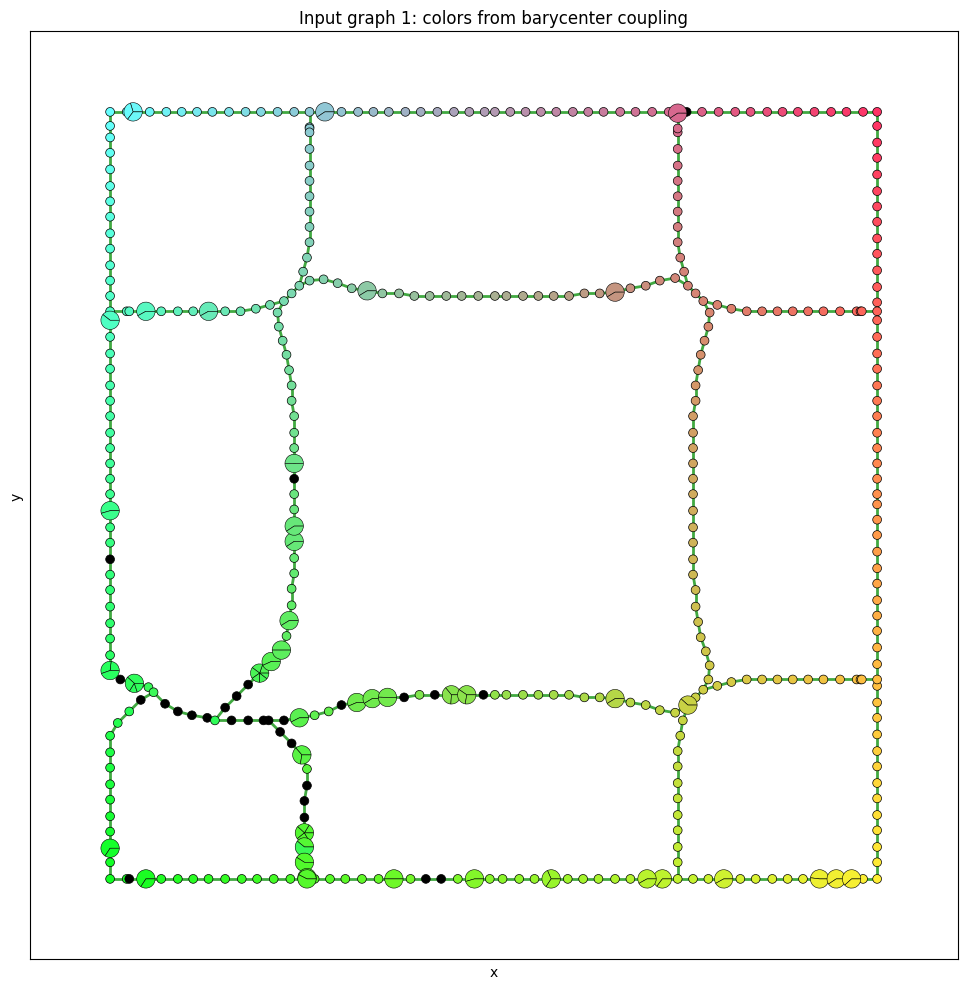

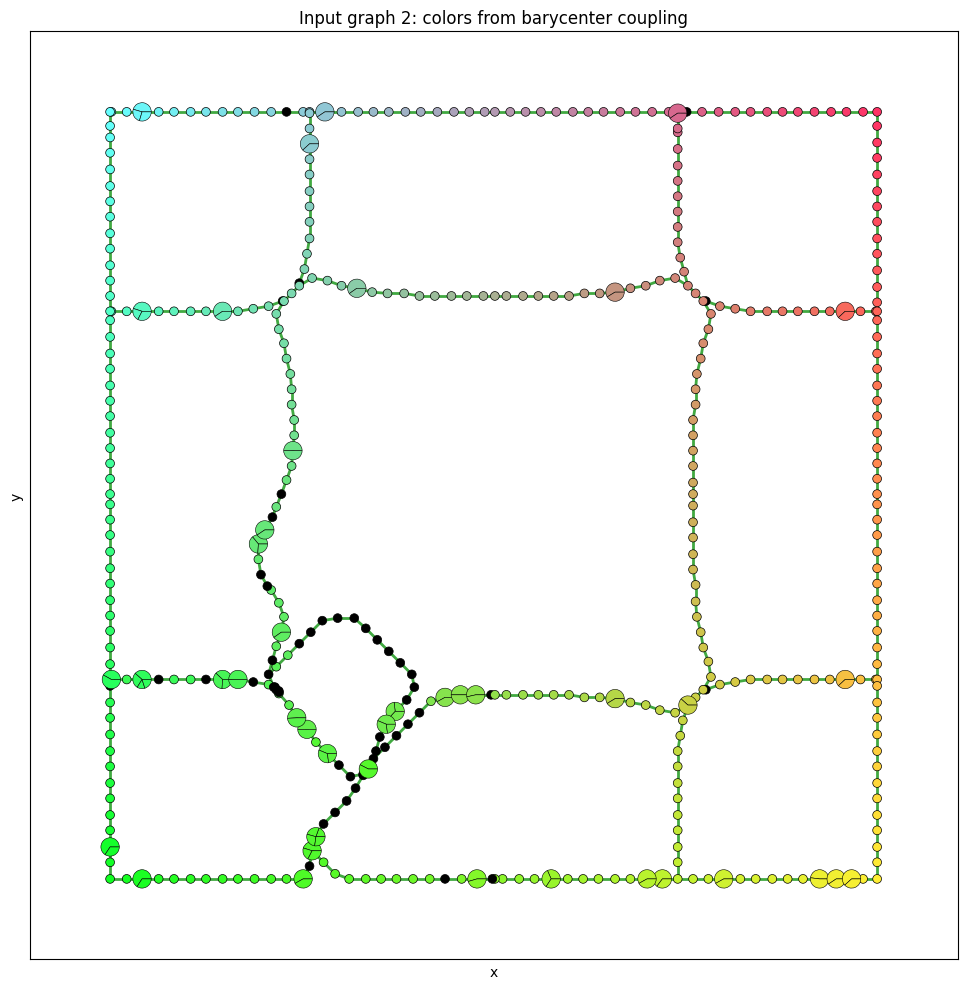

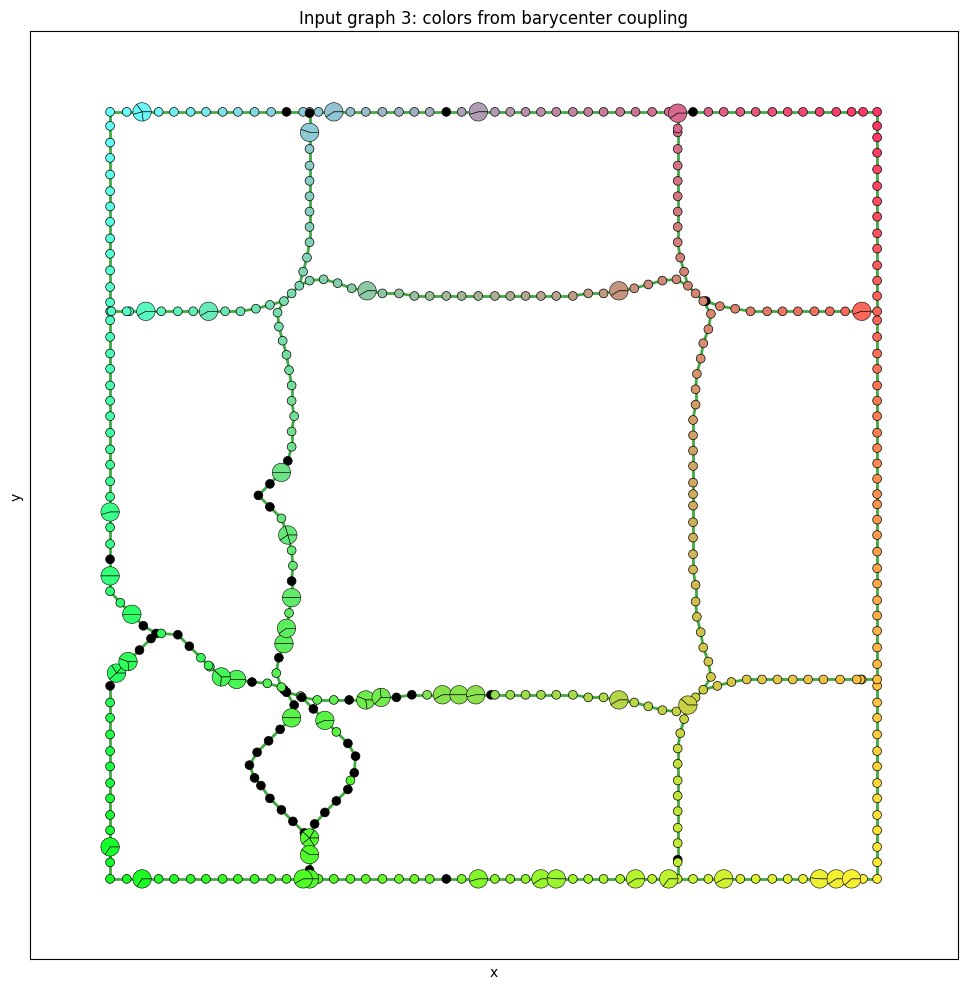

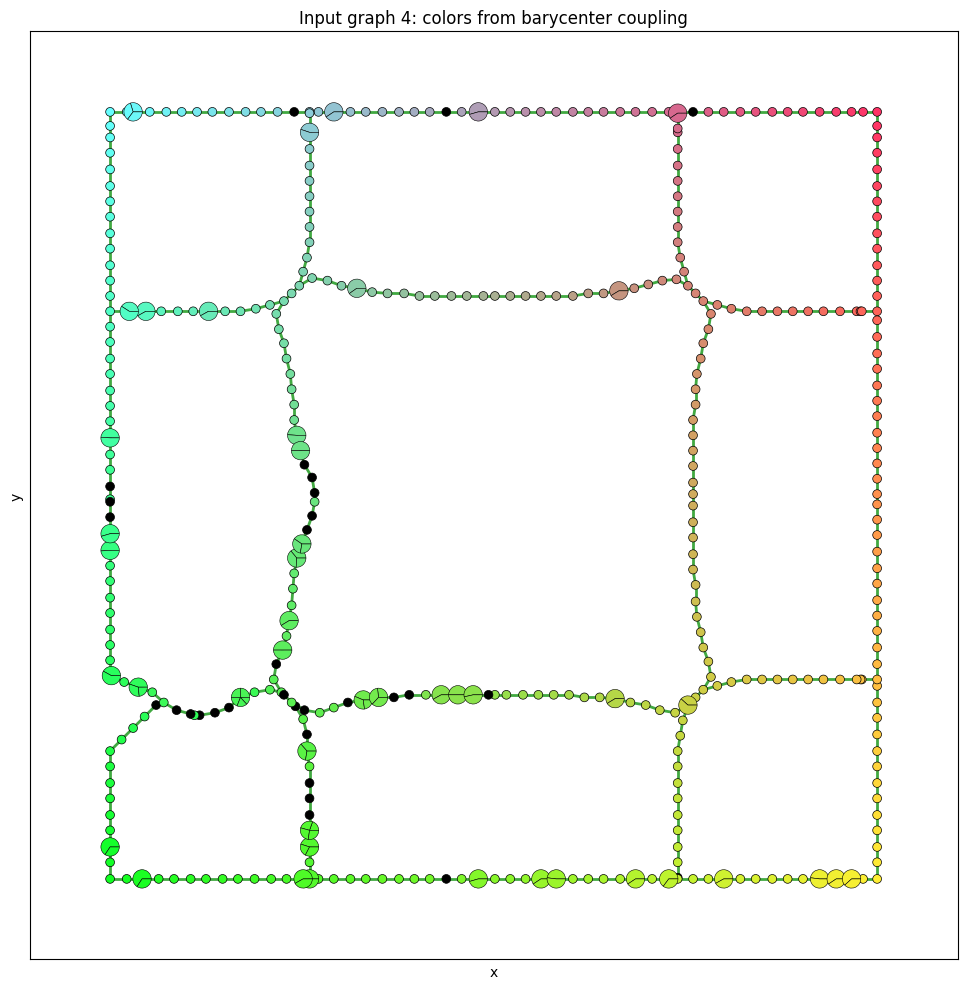

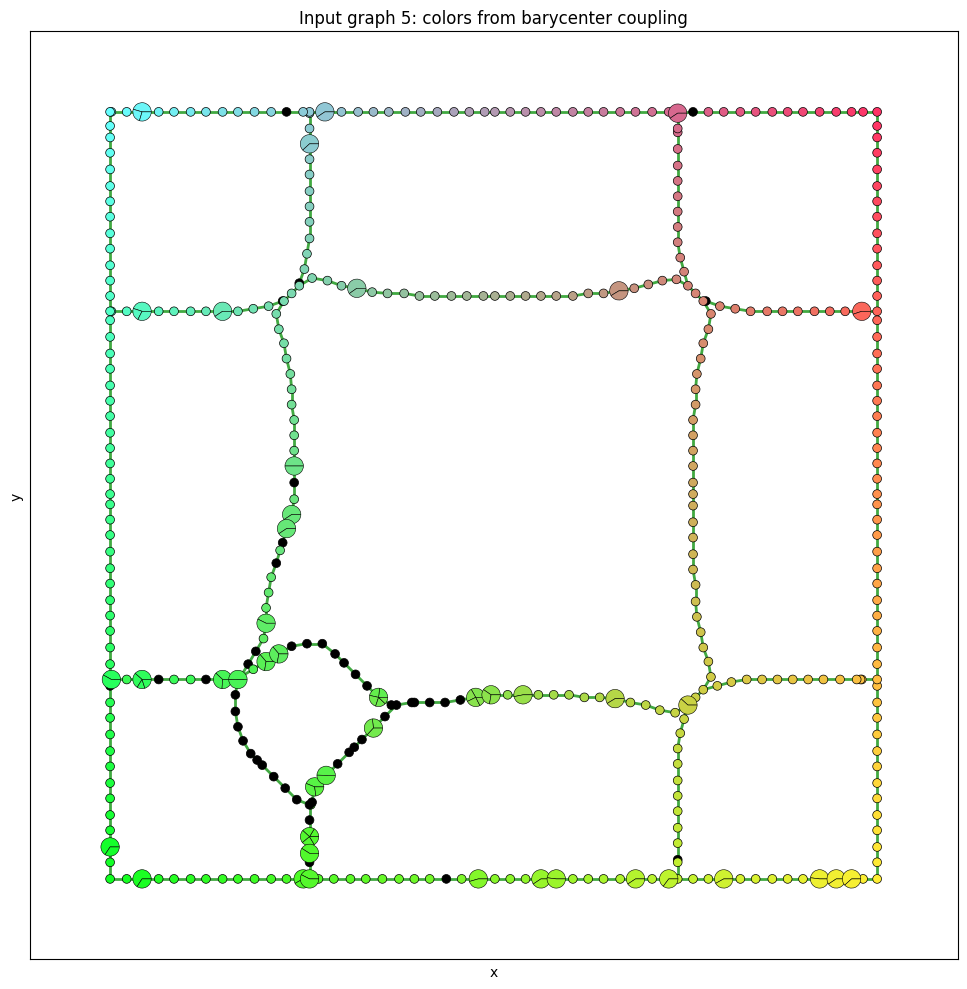

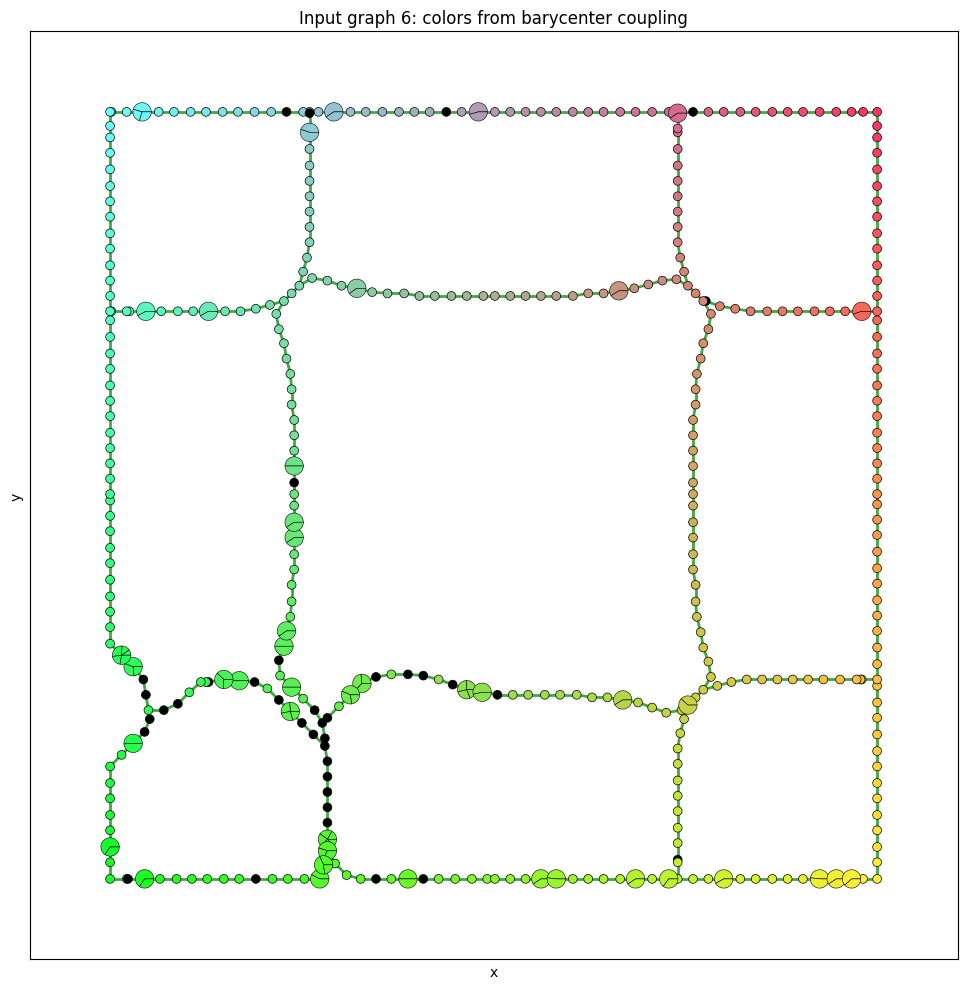

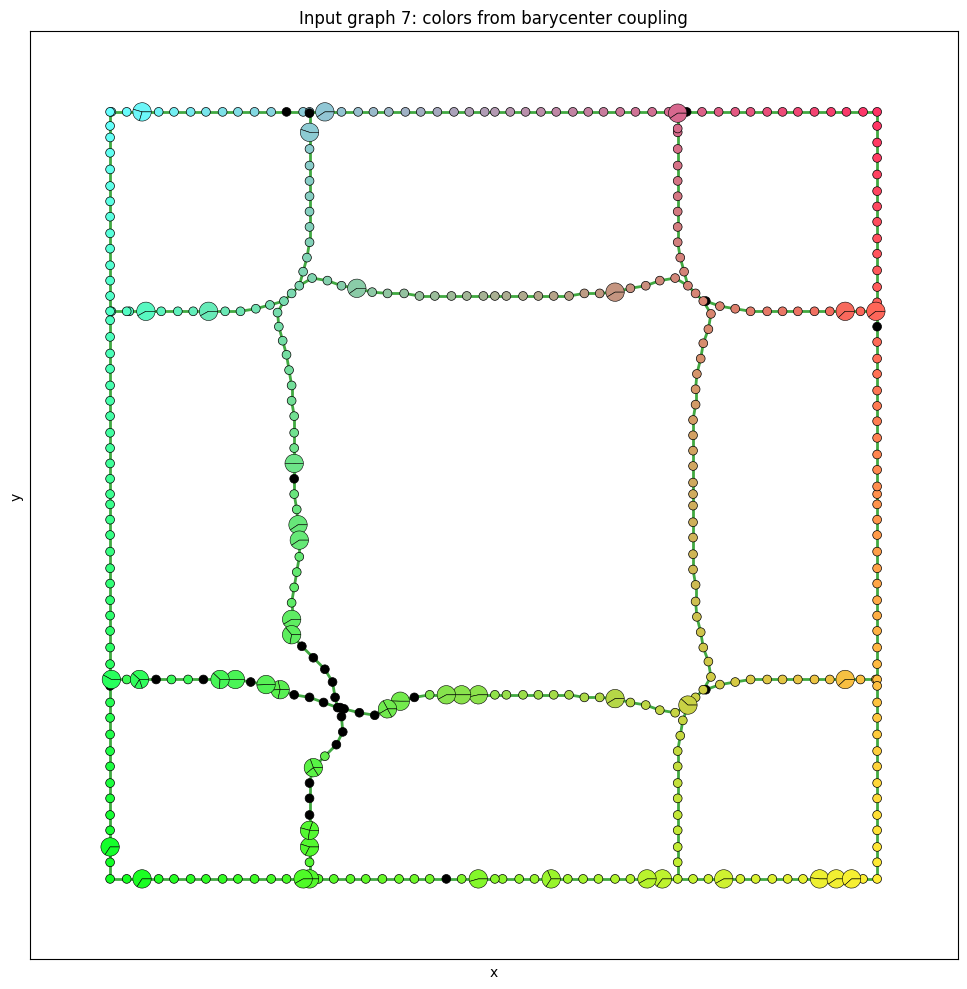

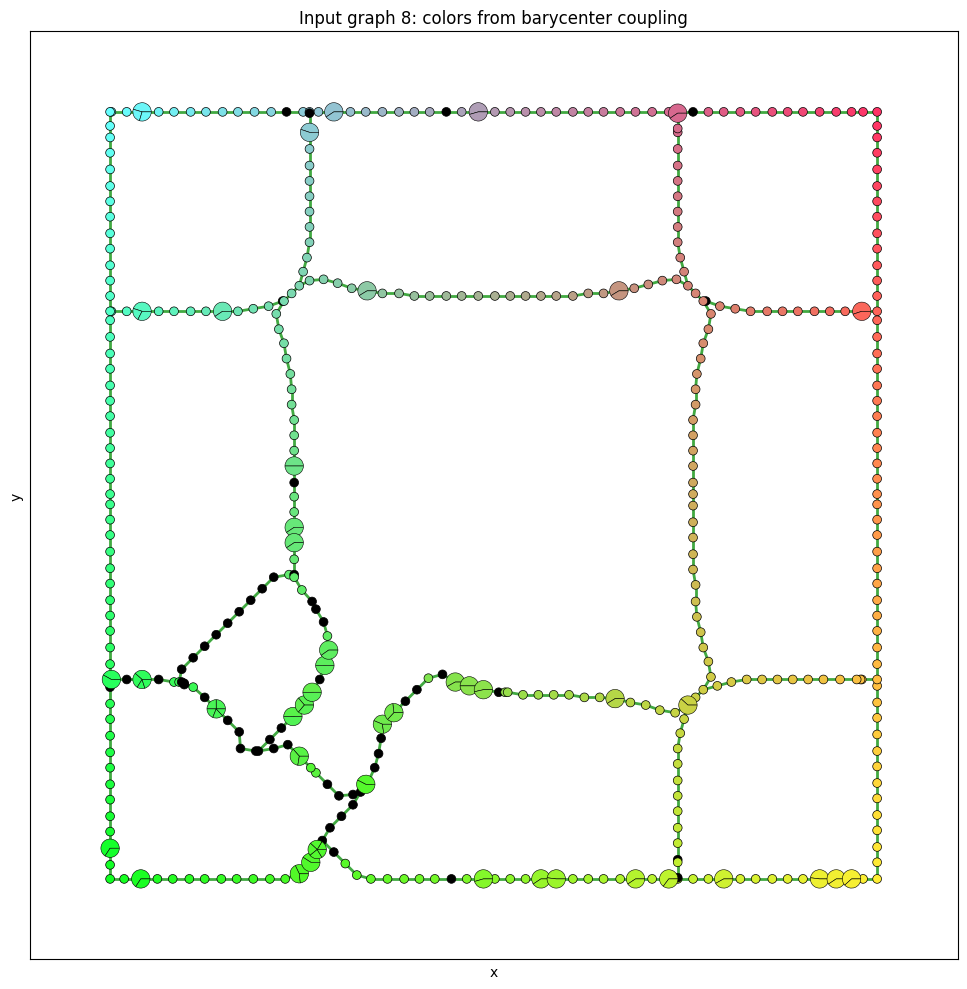

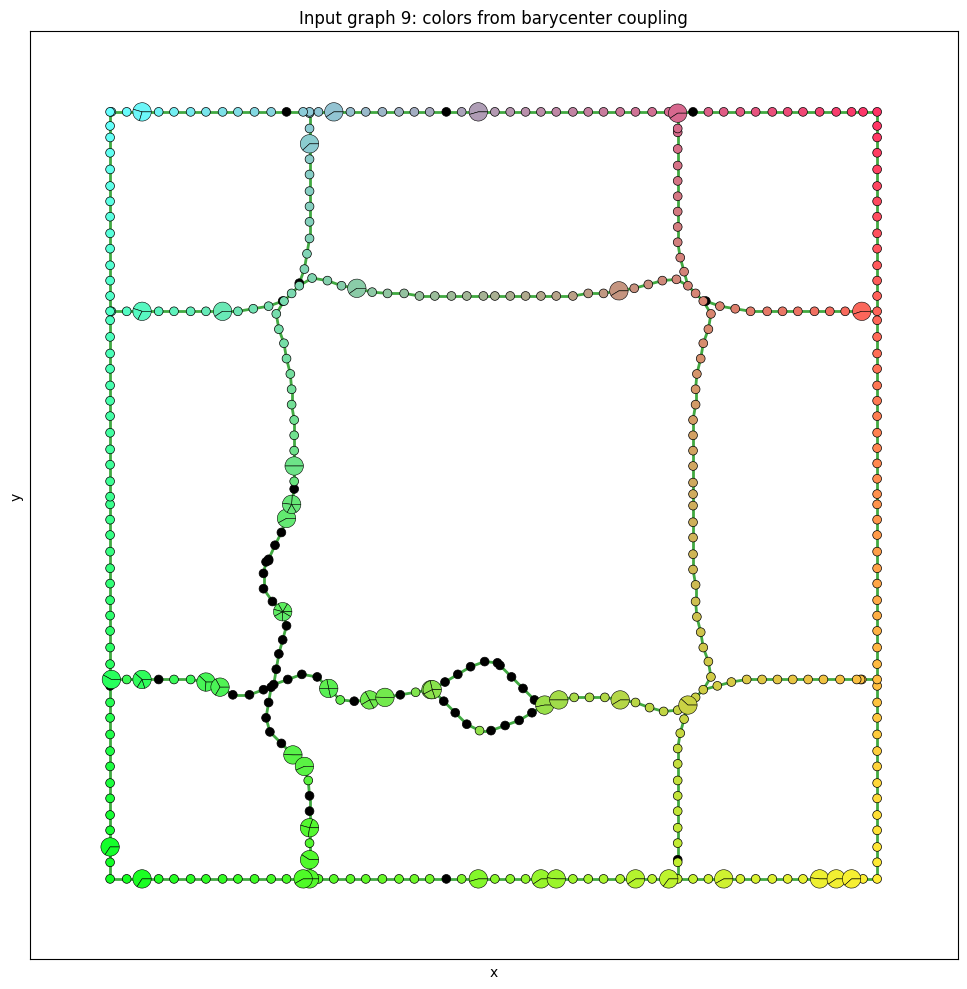

In [32]:
# Color transfer (2): map barycenter colors to each input graph via final PFGW couplings.

_p_bary = log["p"] if "p" in log else p
Ts_final = log["T"]

input_coupling_colors, input_use_pie = transfer_barycenter_colors_to_inputs(
    Ts_final,
    barycenter_node_colors,
    _p_bary,
)

for s, idx in enumerate(idx_list):
    draw_input_graph_coupling_colors(
        Gs[idx],
        nodes_list[idx],
        input_coupling_colors[s],
        input_use_pie[s],
        mesh_id=mesh_ids[idx],
    )


In [33]:
print(len(input_coupling_colors[2]))

425


## Experimental Reconstruction for Barycenter

We construct another pairwise relation matrix B_i for each input. This matrix resembles the idea of adjacency matrix, but it does not assign all pairs that are not directly connected to 0. Instead, for any pair of nodes whose shortest **unweighted** distance is r, their pairwise relation is "q^(r-1)" (0 < q < 1, default q=0.5). 

Then, the barycenter reconstruction will utilize the coupling between the barycenter and inputs, as well as this new pairwise relation matrix.

The idea is as follows:
- We initialize a new relation matrix for reconstruction (which does not replace C_center) to all 0 for the barycenter.
- For each 